<a href="https://colab.research.google.com/github/20deepak28/demand-analysis-project/blob/main/07_streamlit_dashboard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Connecting Google Drive

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Retail-Demand-Forecasting"

print("Project folders:\n")

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)

    if level > 4:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:5]:
        print("  " * (level + 1) + file)

Project folders:



In [ ]:
import os
import shutil
from google.colab import drive

# Unmount stale Drive mount
try:
    drive.flush_and_unmount()
except Exception as e:
    print("Unmount:", e)

# Remove only the local Colab mount directory
mount_path = "/content/drive"

if os.path.exists(mount_path):
    shutil.rmtree(mount_path)

os.makedirs(mount_path, exist_ok=True)

# Mount Google Drive again
drive.mount(mount_path)

print("\nDrive contents:")
print(os.listdir(mount_path))

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive

Drive contents:
['.shortcut-targets-by-id', 'MyDrive', '.Trash-0', '.Encrypted']


### Checking My files

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Retail-Demand-Forecasting"

print("Project exists:", os.path.exists(PROJECT_DIR))

print("\nProject contents:")
for item in os.listdir(PROJECT_DIR):
    path = os.path.join(PROJECT_DIR, item)
    print(f"{item}/" if os.path.isdir(path) else item)

print("\nChecking shortcut folders:")
print(os.listdir("/content/drive/.shortcut-targets-by-id"))


Project exists: True

Project contents:
Data/
models/
notebooks/
README.md/
reports/
dashboard/

Checking shortcut folders:
[]


### Verify Project Data

In [ ]:
import os
import glob

PROJECT_DIR = "/content/drive/MyDrive/Retail-Demand-Forecasting"

# Locate important project folders
for folder in ["Data", "models", "notebooks", "reports"]:
    path = os.path.join(PROJECT_DIR, folder)
    print(f"\n{folder}:")
    print(os.listdir(path)[:15] if os.path.exists(path) else "Not found")

# Find prediction files
prediction_files = glob.glob(
    PROJECT_DIR + "/Data/processed/full_dataset/predictions/*.parquet"
)

# Find inventory files
inventory_files = glob.glob(
    PROJECT_DIR + "/Data/processed/full_dataset/inventory/*"
)

# Find Day 13 analysis files
analysis_files = glob.glob(
    PROJECT_DIR + "/Data/processed/full_dataset/day13_analysis/*"
)

print("\nPrediction chunks:", len(prediction_files))
print("Inventory files:", inventory_files)
print("Day 13 analysis files:", analysis_files)


Data:
['processed', 'raw']

models:
['sample_lightgbm.pkl', 'lstm_feature_scaler.pkl', 'lstm_best.pt', 'model_comparison.json', 'lstm_last.pt', 'retail_demand_lstm_final.pt', 'lstm_best_wape.pt']

notebooks:
['total_daily_sale.png', 'toatl_sale_updated.png', '01_data_exploration.ipynb', 'AVG_SALES_WEEKDAY.png', '02_data_prep.ipynb', 'daily_sales_by_7day_rolling_avg_sample.png', 'daily_sales_by_7day_rolling_avg.png', '03_feature_engineering.ipynb', 'Actual _vs_naive_forecast.png', 'multiple_Actual _vs_naive_forecast.png', 'avg_sale_before_after.png', 'lightgbm_actual_vs_predicted_by_demand.png', 'lightgbm_store_level_wape.png', 'lightgbm_high_error_stores_demand_analysis.png', 'ca4_hobbies_1_178_forecast_error.png']

reports:
['day7_model_improvement_results.csv', 'day7_inventory_policy.csv', 'day8_inventory_simulation_results.csv', 'day8_inventory_simulation_summary.csv', 'day8_inventory_evaluation.csv', 'day8_inventory_performance.png', 'full_dataset_summary.csv', 'full_dataset_quali

# DashBoard Development

In [ ]:
import os
import subprocess
import shutil

# Stop old Streamlit and tunnel processes
subprocess.run("pkill -f 'streamlit run' || true", shell=True)
subprocess.run("pkill -f 'localtunnel' || true", shell=True)

# Reset dashboard folder only
PROJECT_DIR = "/content/drive/MyDrive/Retail-Demand-Forecasting"
DASHBOARD_DIR = os.path.join(PROJECT_DIR, "dashboard")

if os.path.exists(DASHBOARD_DIR):
    shutil.rmtree(DASHBOARD_DIR)

os.makedirs(DASHBOARD_DIR, exist_ok=True)

print("Dashboard reset successfully.")
print("Project data and models are untouched.")

Dashboard reset successfully.
Project data and models are untouched.


### Verify Project data and Instlall Dashboard Libraries

In [ ]:
import os
import glob
import subprocess
import sys

PROJECT_DIR = "/content/drive/MyDrive/Retail-Demand-Forecasting"

required_paths = {
    "LSTM model": "models/retail_demand_lstm_final.pt",
    "Feature scaler": "models/lstm_feature_scaler.pkl",
    "Predictions": "Data/processed/full_dataset/predictions",
    "Inventory": "Data/processed/full_dataset/inventory/inventory_recommendations.parquet",
    "Risk analysis": "Data/processed/full_dataset/day13_analysis/inventory_risk_analysis.parquet",
    "Category analysis": "Data/processed/full_dataset/day13_analysis/category_error_summary.csv",
    "Store analysis": "Data/processed/full_dataset/day13_analysis/store_error_summary.csv"
}

for name, path in required_paths.items():
    full_path = os.path.join(PROJECT_DIR, path)
    exists = os.path.exists(full_path)
    print(f"{'✅' if exists else '❌'} {name}")

prediction_files = glob.glob(
    os.path.join(PROJECT_DIR, "Data/processed/full_dataset/predictions/*.parquet")
)
print(f"\nPrediction chunks: {len(prediction_files)}")

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "streamlit", "plotly"],
    check=True
)

print("\n✅ Dashboard libraries installed.")

✅ LSTM model
✅ Feature scaler
✅ Predictions
✅ Inventory
✅ Risk analysis
✅ Category analysis
✅ Store analysis

Prediction chunks: 31

✅ Dashboard libraries installed.


### Inspect Dashboard data structure

In [ ]:
import os
import pandas as pd

BASE = "/content/drive/MyDrive/Retail-Demand-Forecasting"

risk = pd.read_parquet(
    f"{BASE}/Data/processed/full_dataset/day13_analysis/inventory_risk_analysis.parquet"
)
category = pd.read_csv(
    f"{BASE}/Data/processed/full_dataset/day13_analysis/category_error_summary.csv"
)
store = pd.read_csv(
    f"{BASE}/Data/processed/full_dataset/day13_analysis/store_error_summary.csv"
)
inventory = pd.read_parquet(
    f"{BASE}/Data/processed/full_dataset/inventory/inventory_recommendations.parquet"
)

print("RISK COLUMNS:\n", risk.columns.tolist())
print("\nCATEGORY COLUMNS:\n", category.columns.tolist())
print("\nSTORE COLUMNS:\n", store.columns.tolist())
print("\nINVENTORY COLUMNS:\n", inventory.columns.tolist())

print("\nRISK LEVELS:\n", risk["risk_level"].value_counts())

RISK COLUMNS:
 ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'absolute_error', 'squared_error', 'actual_sales', 'observations', 'MAE', 'RMSE', 'WAPE', 'avg_daily_demand', 'demand_std', 'safety_stock', 'reorder_point', 'error_rank', 'safety_stock_rank', 'inventory_risk_score', 'risk_level']

CATEGORY COLUMNS:
 ['cat_id', 'absolute_error', 'actual_sales', 'squared_error_mean', 'observations', 'MAE', 'RMSE', 'WAPE']

STORE COLUMNS:
 ['store_id', 'absolute_error', 'actual_sales', 'squared_error', 'observations', 'MAE', 'RMSE', 'WAPE']

INVENTORY COLUMNS:
 ['id', 'avg_daily_demand', 'demand_std', 'safety_stock', 'reorder_point']

RISK LEVELS:
 risk_level
Low         15681
Medium       7801
High         4282
Critical     2726
Name: count, dtype: int64


## Create the Streamlit Dashboard

In [ ]:

%%writefile /content/drive/MyDrive/Retail-Demand-Forecasting/dashboard/app.py

import os
import glob
import streamlit as st
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# --------------------------------------------------
# CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Retail Intelligence | Demand Forecasting",
    page_icon="📊",
    layout="wide"
)

PROJECT_DIR = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))

ANALYSIS_DIR = os.path.join(
    PROJECT_DIR, "Data/processed/full_dataset/day13_analysis"
)

INVENTORY_DIR = os.path.join(
    PROJECT_DIR, "Data/processed/full_dataset/inventory"
)

PREDICTION_DIR = os.path.join(
    PROJECT_DIR, "Data/processed/full_dataset/predictions"
)

# --------------------------------------------------
# CUSTOM CSS
# --------------------------------------------------

st.markdown("""
<style>
    .main {
        background-color: #0e1117;
    }

    [data-testid="stMetric"] {
        background-color: #1c2333;
        padding: 18px;
        border-radius: 12px;
        border: 1px solid #30394d;
    }

    [data-testid="stMetricLabel"] {
        color: #aab4c5;
    }

    [data-testid="stMetricValue"] {
        color: #ffffff;
    }

    h1, h2, h3 {
        color: #f1f5f9;
    }

    .subtitle {
        color: #94a3b8;
        font-size: 15px;
    }

    .section-header {
        padding-top: 15px;
        padding-bottom: 5px;
    }
</style>
""", unsafe_allow_html=True)

# --------------------------------------------------
# DATA LOADING
# --------------------------------------------------

@st.cache_data(show_spinner="Loading dashboard data...")
def load_data():

    risk = pd.read_parquet(
        os.path.join(ANALYSIS_DIR, "inventory_risk_analysis.parquet")
    )

    category = pd.read_csv(
        os.path.join(ANALYSIS_DIR, "category_error_summary.csv")
    )

    store = pd.read_csv(
        os.path.join(ANALYSIS_DIR, "store_error_summary.csv")
    )

    inventory = pd.read_parquet(
        os.path.join(INVENTORY_DIR, "inventory_recommendations.parquet")
    )

    return risk, category, store, inventory


@st.cache_data(show_spinner="Loading forecast sample...")
def load_prediction_sample(chunk_number):

    files = sorted(
        glob.glob(os.path.join(PREDICTION_DIR, "*.parquet"))
    )

    if not files:
        return pd.DataFrame()

    chunk_number = min(chunk_number, len(files) - 1)

    df = pd.read_parquet(files[chunk_number])

    if "date" in df.columns:
        df["date"] = pd.to_datetime(df["date"])

    return df


risk, category, store, inventory = load_data()

# --------------------------------------------------
# SIDEBAR
# --------------------------------------------------

st.sidebar.title("📊 Retail Intelligence")

st.sidebar.caption("Demand Forecasting & Inventory Optimization")

page = st.sidebar.radio(
    "NAVIGATION",
    [
        "Executive Overview",
        "Demand Forecast Analysis",
        "Model Performance Comparison",
        "Store & Category Analysis",
        "Inventory Optimization",
        "High-Risk Product Monitoring"
    ]
)

st.sidebar.markdown("---")
st.sidebar.markdown("### Project Information")
st.sidebar.write("Dataset: Walmart M5")
st.sidebar.write("Forecast Model: LSTM")
st.sidebar.write("Framework: PyTorch")
st.sidebar.write("Dashboard: Streamlit")

st.sidebar.markdown("---")
st.sidebar.caption("Retail Demand Forecasting Project")

# --------------------------------------------------
# COMMON METRICS
# --------------------------------------------------

total_products = risk["id"].nunique()
total_stores = risk["store_id"].nunique()
critical_products = (risk["risk_level"] == "Critical").sum()
high_risk_products = risk["risk_level"].isin(
    ["High", "Critical"]
).sum()

risk_order = ["Low", "Medium", "High", "Critical"]

risk_counts = (
    risk["risk_level"]
    .value_counts()
    .reindex(risk_order, fill_value=0)
    .reset_index()
)

risk_counts.columns = ["Risk Level", "Products"]

# --------------------------------------------------
# PAGE 1: EXECUTIVE OVERVIEW
# --------------------------------------------------

if page == "Executive Overview":

    st.title("📊 Retail Intelligence Dashboard")

    st.markdown(
        '<p class="subtitle">Demand forecasting, model performance '
        'and inventory risk monitoring</p>',
        unsafe_allow_html=True
    )

    st.markdown("---")

    col1, col2, col3, col4 = st.columns(4)

    col1.metric("Product-Store Pairs", f"{total_products:,}")
    col2.metric("Validation Predictions", "12.53M")
    col3.metric("Stores", total_stores)
    col4.metric("Critical Risk", f"{critical_products:,}")

    st.markdown("## Model Performance")

    c1, c2, c3 = st.columns(3)

    c1.metric("LSTM MAE", "0.8879")
    c2.metric("LSTM RMSE", "2.1497")
    c3.metric("LSTM WAPE", "68.36%")

    st.caption(
        "Selected model: Epoch 5 | Validation: 08-Apr-2015 to 22-May-2016"
    )

    st.markdown("---")
    st.markdown("## Inventory Risk Overview")

    left, right = st.columns(2)

    with left:
        fig = px.bar(
            risk_counts,
            x="Risk Level",
            y="Products",
            color="Risk Level",
            title="Products by Inventory Risk Level",
            color_discrete_map={
                "Low": "#16a34a",
                "Medium": "#eab308",
                "High": "#f97316",
                "Critical": "#dc2626"
            }
        )
        fig.update_layout(template="plotly_dark")
        st.plotly_chart(fig, use_container_width=True)

    with right:
        fig = px.pie(
            risk_counts,
            names="Risk Level",
            values="Products",
            hole=0.55,
            title="Inventory Risk Distribution",
            color="Risk Level",
            color_discrete_map={
                "Low": "#16a34a",
                "Medium": "#eab308",
                "High": "#f97316",
                "Critical": "#dc2626"
            }
        )
        fig.update_layout(template="plotly_dark")
        st.plotly_chart(fig, use_container_width=True)

    st.markdown("## Category Performance")

    fig = px.bar(
        category,
        x="cat_id",
        y="WAPE",
        color="cat_id",
        text_auto=".2f",
        title="Forecast WAPE by Category"
    )
    fig.update_layout(
        template="plotly_dark",
        yaxis_title="WAPE (%)",
        xaxis_title="Category"
    )
    st.plotly_chart(fig, use_container_width=True)

    st.markdown("## Critical Risk Products")

    critical = (
        risk[risk["risk_level"] == "Critical"]
        .sort_values("inventory_risk_score", ascending=False)
        .head(10)
    )

    st.dataframe(
        critical[
            [
                "id", "store_id", "cat_id",
                "MAE", "WAPE", "safety_stock",
                "reorder_point", "inventory_risk_score"
            ]
        ],
        use_container_width=True,
        hide_index=True
    )

# --------------------------------------------------
# PAGE 2: DEMAND FORECAST ANALYSIS
# --------------------------------------------------

elif page == "Demand Forecast Analysis":

    st.title("📈 Demand Forecast Analysis")

    st.markdown(
        "Explore actual sales and LSTM predictions from the validation dataset."
    )

    prediction_files = sorted(
        glob.glob(os.path.join(PREDICTION_DIR, "*.parquet"))
    )

    if prediction_files:

        selected_chunk = st.selectbox(
            "Select prediction chunk",
            options=list(range(len(prediction_files))),
            format_func=lambda x: f"Chunk {x + 1} of {len(prediction_files)}"
        )

        predictions = load_prediction_sample(selected_chunk)

        if not predictions.empty:

            stores = sorted(predictions["store_id"].dropna().unique())

            selected_store = st.selectbox(
                "Select store",
                stores
            )

            store_data = predictions[
                predictions["store_id"] == selected_store
            ].copy()

            products = sorted(store_data["id"].dropna().unique())

            selected_product = st.selectbox(
                "Select product-store series",
                products
            )

            product_data = store_data[
                store_data["id"] == selected_product
            ].sort_values("date")

            if not product_data.empty:

                fig = go.Figure()

                fig.add_trace(
                    go.Scatter(
                        x=product_data["date"],
                        y=product_data["sales"],
                        name="Actual Sales",
                        mode="lines"
                    )
                )

                fig.add_trace(
                    go.Scatter(
                        x=product_data["date"],
                        y=product_data["lstm_prediction"],
                        name="LSTM Prediction",
                        mode="lines"
                    )
                )

                fig.update_layout(
                    title=f"Actual vs Predicted Demand: {selected_product}",
                    template="plotly_dark",
                    xaxis_title="Date",
                    yaxis_title="Sales",
                    hovermode="x unified"
                )

                st.plotly_chart(fig, use_container_width=True)

                mae = (
                    product_data["sales"] -
                    product_data["lstm_prediction"]
                ).abs().mean()

                c1, c2, c3 = st.columns(3)

                c1.metric(
                    "Actual Average Sales",
                    f"{product_data['sales'].mean():.2f}"
                )

                c2.metric(
                    "Predicted Average Sales",
                    f"{product_data['lstm_prediction'].mean():.2f}"
                )

                c3.metric(
                    "Series MAE",
                    f"{mae:.3f}"
                )

                st.dataframe(
                    product_data[
                        ["date", "sales", "lstm_prediction"]
                    ].tail(20),
                    use_container_width=True,
                    hide_index=True
                )

    else:
        st.error("No prediction files found.")

# --------------------------------------------------
# PAGE 3: MODEL COMPARISON
# --------------------------------------------------

elif page == "Model Performance Comparison":

    st.title("⚖️ Model Performance Comparison")

    st.markdown("Comparison of LightGBM and LSTM on the validation dataset.")

    comparison = pd.DataFrame({
        "Model": ["LightGBM", "LSTM"],
        "MAE": [0.930733, 0.887898],
        "RMSE": [2.006124, 2.149657],
        "WAPE": [71.662936, 68.36]
    })

    st.dataframe(
        comparison.style.format({
            "MAE": "{:.4f}",
            "RMSE": "{:.4f}",
            "WAPE": "{:.2f}%"
        }),
        use_container_width=True,
        hide_index=True
    )

    st.markdown("## Metric Comparison")

    metric = st.selectbox(
        "Select evaluation metric",
        ["MAE", "RMSE", "WAPE"]
    )

    fig = px.bar(
        comparison,
        x="Model",
        y=metric,
        color="Model",
        text_auto=".4f",
        title=f"{metric} Comparison"
    )

    fig.update_layout(template="plotly_dark")
    st.plotly_chart(fig, use_container_width=True)

    st.markdown("## Model Observations")

    st.info(
        "LSTM achieved lower MAE and WAPE. "
        "LightGBM achieved lower RMSE. "
        "The better model depends on the evaluation metric."
    )

    st.markdown("### LSTM Configuration")

    st.write({
        "Architecture": "2-layer LSTM",
        "Hidden Units": 128,
        "Input Features": 14,
        "Future Features": 8,
        "Sequence Length": 28,
        "Parameters": 216481,
        "Selected Epoch": 5
    })

# --------------------------------------------------
# PAGE 4: STORE & CATEGORY ANALYSIS
# --------------------------------------------------

elif page == "Store & Category Analysis":

    st.title("🏬 Store & Category Analysis")

    st.markdown("Analyze forecasting errors across stores and product categories.")

    st.markdown("## Store Performance")

    store_metric = st.selectbox(
        "Store evaluation metric",
        ["MAE", "RMSE", "WAPE"],
        key="store_metric"
    )

    store_sorted = store.sort_values(
        store_metric,
        ascending=False
    )

    fig = px.bar(
        store_sorted,
        x="store_id",
        y=store_metric,
        color=store_metric,
        text_auto=".3f",
        title=f"Store-wise {store_metric}"
    )

    fig.update_layout(template="plotly_dark")
    st.plotly_chart(fig, use_container_width=True)

    st.dataframe(
        store.sort_values("WAPE", ascending=False),
        use_container_width=True,
        hide_index=True
    )

    st.markdown("---")
    st.markdown("## Category Performance")

    category_metric = st.selectbox(
        "Category evaluation metric",
        ["MAE", "RMSE", "WAPE"],
        key="category_metric"
    )

    fig = px.bar(
        category,
        x="cat_id",
        y=category_metric,
        color=category_metric,
        text_auto=".3f",
        title=f"Category-wise {category_metric}"
    )

    fig.update_layout(template="plotly_dark")
    st.plotly_chart(fig, use_container_width=True)

    st.dataframe(
        category,
        use_container_width=True,
        hide_index=True
    )

# --------------------------------------------------
# PAGE 5: INVENTORY OPTIMIZATION
# --------------------------------------------------

elif page == "Inventory Optimization":

    st.title("📦 Inventory Optimization")

    st.markdown(
        "Demand-based safety stock and reorder point recommendations."
    )

    c1, c2, c3 = st.columns(3)

    c1.metric(
        "Average Safety Stock",
        f"{inventory['safety_stock'].mean():.2f}"
    )

    c2.metric(
        "Average Reorder Point",
        f"{inventory['reorder_point'].mean():.2f}"
    )

    c3.metric(
        "Product-Store Pairs",
        f"{len(inventory):,}"
    )

    st.markdown("---")

    fig = px.histogram(
        inventory,
        x="safety_stock",
        nbins=50,
        title="Safety Stock Distribution"
    )

    fig.update_layout(template="plotly_dark")
    st.plotly_chart(fig, use_container_width=True)

    fig = px.scatter(
        inventory.sample(
            min(3000, len(inventory)),
            random_state=42
        ),
        x="avg_daily_demand",
        y="reorder_point",
        size="safety_stock",
        color="safety_stock",
        hover_data=["id"],
        title="Daily Demand vs Reorder Point"
    )

    fig.update_layout(template="plotly_dark")
    st.plotly_chart(fig, use_container_width=True)

    st.markdown("## Inventory Recommendations")

    search_product = st.text_input(
        "Search product-store ID"
    )

    filtered_inventory = inventory.copy()

    if search_product:
        filtered_inventory = filtered_inventory[
            filtered_inventory["id"].str.contains(
                search_product,
                case=False,
                na=False
            )
        ]

    st.dataframe(
        filtered_inventory.head(500),
        use_container_width=True,
        hide_index=True
    )

    st.download_button(
        "⬇️ Download Inventory Recommendations",
        data=inventory.to_csv(index=False).encode("utf-8"),
        file_name="inventory_recommendations.csv",
        mime="text/csv"
    )

    st.caption(
        "Assumptions: 7-day lead time and 95% service level. "
        "These are model-based recommendations, not live inventory alerts."
    )

# --------------------------------------------------
# PAGE 6: HIGH-RISK PRODUCT MONITORING
# --------------------------------------------------

elif page == "High-Risk Product Monitoring":

    st.title("🚨 High-Risk Product Monitoring")

    st.markdown(
        "Identify product-store combinations requiring inventory attention."
    )

    selected_risk = st.multiselect(
        "Select risk levels",
        risk_order,
        default=["High", "Critical"]
    )

    filtered_risk = risk[
        risk["risk_level"].isin(selected_risk)
    ].copy()

    c1, c2, c3 = st.columns(3)

    c1.metric(
        "Selected Products",
        f"{len(filtered_risk):,}"
    )

    c2.metric(
        "Average Risk Score",
        f"{filtered_risk['inventory_risk_score'].mean():.2f}"
        if not filtered_risk.empty else "N/A"
    )

    c3.metric(
        "Critical Products",
        f"{(filtered_risk['risk_level'] == 'Critical').sum():,}"
    )

    st.markdown("## Risk Score Distribution")

    fig = px.histogram(
        filtered_risk,
        x="inventory_risk_score",
        color="risk_level",
        nbins=40,
        title="Inventory Risk Score Distribution"
    )

    fig.update_layout(template="plotly_dark")
    st.plotly_chart(fig, use_container_width=True)

    st.markdown("## Highest Risk Products")

    top_n = st.slider(
        "Number of products",
        min_value=5,
        max_value=100,
        value=20
    )

    top_risk = filtered_risk.sort_values(
        "inventory_risk_score",
        ascending=False
    ).head(top_n)

    st.dataframe(
        top_risk[
            [
                "id",
                "item_id",
                "store_id",
                "cat_id",
                "MAE",
                "RMSE",
                "WAPE",
                "safety_stock",
                "reorder_point",
                "inventory_risk_score",
                "risk_level"
            ]
        ],
        use_container_width=True,
        hide_index=True
    )

    st.download_button(
        "⬇️ Download Risk Analysis",
        data=filtered_risk.to_csv(index=False).encode("utf-8"),
        file_name="inventory_risk_analysis.csv",
        mime="text/csv"
    )

    st.caption(
        "Risk score is a project-defined prioritization score combining "
        "forecast error rank and safety stock rank. "
        "It is not a validated stockout probability."
    )

# --------------------------------------------------
# FOOTER
# --------------------------------------------------

st.markdown("---")

st.markdown(
    """
    <div style="text-align:center; color:#64748b; padding:10px;">
        Retail Demand Forecasting & Inventory Optimization |
        Built with Python, PyTorch, Streamlit and Plotly
    </div>
    """,
    unsafe_allow_html=True
)

Writing /content/drive/MyDrive/Retail-Demand-Forecasting/dashboard/app.py


## Start Streamlit

In [ ]:
!streamlit run /content/drive/MyDrive/Retail-Demand-Forecasting/dashboard/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!cat /content/streamlit.log

## Check the streamlit server

In [ ]:
import requests
import subprocess
import time

print("Checking Streamlit server...")

try:
    response = requests.get("http://127.0.0.1:8501", timeout=5)
    print("✅ Streamlit is responding:", response.status_code)
except Exception:
    print("❌ Streamlit is not responding. Restarting...")

    subprocess.run("pkill -f 'streamlit run' || true", shell=True)

    subprocess.Popen(
        [
            "streamlit", "run",
            "/content/drive/MyDrive/Retail-Demand-Forecasting/dashboard/app.py",
            "--server.port", "8501",
            "--server.address", "0.0.0.0",
            "--server.headless", "true"
        ],
        stdout=open("/content/streamlit.log", "w"),
        stderr=subprocess.STDOUT
    )

    time.sleep(10)

    try:
        response = requests.get("http://127.0.0.1:8501", timeout=10)
        print("✅ Streamlit is responding:", response.status_code)
    except Exception as e:
        print("❌ Server error:", e)

print("\nSERVER LOG:")
print(open("/content/streamlit.log").read()[-3000:])

Checking Streamlit server...
❌ Streamlit is not responding. Restarting...
✅ Streamlit is responding: 200

SERVER LOG:


2026-11-06 13:43:10.842 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.150.187.95:8501




In [ ]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501, height=900)

<IPython.core.display.Javascript object>

In [ ]:
import subprocess
import time
import re

# Download Cloudflare Tunnel
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared

# Start tunnel
tunnel = subprocess.Popen(
    ["/content/cloudflared", "tunnel", "--url", "http://localhost:8501"],
    stdout=open("/content/cloudflare.log", "w"),
    stderr=subprocess.STDOUT
)

# Wait for public URL
url = None

for _ in range(30):
    time.sleep(2)
    with open("/content/cloudflare.log") as f:
        log = f.read()

    match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", log)

    if match:
        url = match.group(0)
        break

if url:
    print("✅ YOUR DASHBOARD LINK:")
    print(url)
else:
    print("Tunnel URL not generated. Log:")
    print(log[-2000:])

✅ YOUR DASHBOARD LINK:
https://roberts-founded-tension-issue.trycloudflare.com


# Actual Future Demand Forecasting

### INspect forecasting data

In [ ]:
import os
import glob
import pandas as pd

BASE = "/content/drive/MyDrive/Retail-Demand-Forecasting"

print("PROJECT DATA FILES\n")

for root, dirs, files in os.walk(os.path.join(BASE, "Data")):
    dirs[:] = [d for d in dirs if d not in ["__pycache__"]]
    for file in files:
        if file.endswith((".csv", ".parquet")):
            print(os.path.relpath(os.path.join(root, file), BASE))

print("\nLATEST PREDICTION CHUNK")

prediction_dir = os.path.join(
    BASE, "Data/processed/full_dataset/predictions"
)

files = sorted(glob.glob(os.path.join(prediction_dir, "*.parquet")))

df = pd.read_parquet(files[-1])

print("Latest date:", df["date"].max())
print("Columns:", df.columns.tolist())
print("Sample:")
print(df.head(3))

PROJECT DATA FILES

Data/processed/feature_engineered_sample.parquet
Data/processed/sales_sample.csv
Data/processed/feature_engineered_sample.csv
Data/processed/full_dataset/sales_chunk_000.parquet
Data/processed/full_dataset/sales_chunk_001.parquet
Data/processed/full_dataset/sales_chunk_002.parquet
Data/processed/full_dataset/sales_chunk_003.parquet
Data/processed/full_dataset/sales_chunk_004.parquet
Data/processed/full_dataset/sales_chunk_005.parquet
Data/processed/full_dataset/sales_chunk_006.parquet
Data/processed/full_dataset/sales_chunk_007.parquet
Data/processed/full_dataset/sales_chunk_008.parquet
Data/processed/full_dataset/sales_chunk_009.parquet
Data/processed/full_dataset/sales_chunk_010.parquet
Data/processed/full_dataset/sales_chunk_011.parquet
Data/processed/full_dataset/sales_chunk_012.parquet
Data/processed/full_dataset/sales_chunk_013.parquet
Data/processed/full_dataset/sales_chunk_014.parquet
Data/processed/full_dataset/sales_chunk_015.parquet
Data/processed/full_da

### Check future feature availabilty

In [ ]:
import os
import pandas as pd

BASE = "/content/drive/MyDrive/Retail-Demand-Forecasting"

calendar_path = f"{BASE}/Data/raw/m5-forecasting-accuracy/calendar.csv"
prices_path = f"{BASE}/Data/raw/m5-forecasting-accuracy/sell_prices.csv"

calendar = pd.read_csv(calendar_path)
calendar["date"] = pd.to_datetime(calendar["date"])

future_calendar = calendar[
    (calendar["date"] > "2016-05-22") &
    (calendar["date"] <= "2016-06-19")
]

print("FUTURE CALENDAR")
print("Available dates:", len(future_calendar))
print(future_calendar[["date", "wm_yr_wk", "event_name_1", "event_name_2"]].head())
print(future_calendar[["date", "wm_yr_wk"]].tail())

print("\nFUTURE PRICE COVERAGE")

prices = pd.read_csv(prices_path)

future_weeks = future_calendar["wm_yr_wk"].unique()

print("Future weeks:", len(future_weeks))
print("Price records for future weeks:",
      prices[prices["wm_yr_wk"].isin(future_weeks)].shape[0])

print("\nFEATURE DATA CHECK")

feature_path = (
    f"{BASE}/Data/processed/full_dataset/featured/sales_chunk_030.parquet"
)

features = pd.read_parquet(feature_path)

print("Feature columns:", features.columns.tolist())
print("Latest feature date:", features["date"].max())
print("Feature shape:", features.shape)

FUTURE CALENDAR
Available dates: 28
           date  wm_yr_wk event_name_1 event_name_2
1941 2016-05-23     11617          NaN          NaN
1942 2016-05-24     11617          NaN          NaN
1943 2016-05-25     11617          NaN          NaN
1944 2016-05-26     11617          NaN          NaN
1945 2016-05-27     11617          NaN          NaN
           date  wm_yr_wk
1964 2016-06-15     11620
1965 2016-06-16     11620
1966 2016-06-17     11620
1967 2016-06-18     11621
1968 2016-06-19     11621

FUTURE PRICE COVERAGE
Future weeks: 5
Price records for future weeks: 152450

FEATURE DATA CHECK
Feature columns: ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'date', 'weekday', 'month', 'year', 'event_name_1', 'event_type_1', 'snap_CA', 'snap_TX', 'snap_WI', 'wm_yr_wk', 'sell_price', 'revenue', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'day_of_week', 'is_event']
Latest feature date: 2016-05-22 00:00:00
Feature shape: (951090, 27)


### Verify model and feature scaler

In [ ]:
import torch
import joblib
import os

BASE = "/content/drive/MyDrive/Retail-Demand-Forecasting"

model_path = f"{BASE}/models/retail_demand_lstm_final.pt"
scaler_path = f"{BASE}/models/lstm_feature_scaler.pkl"

checkpoint = torch.load(
    model_path,
    map_location="cpu",
    weights_only=False
)

scaler = joblib.load(scaler_path)

print("MODEL CHECKPOINT")
print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

print("\nFEATURE SCALER")
print("Scaler type:", type(scaler))
print("Feature count:", scaler.n_features_in_)

print("\nMODEL FILE SIZE:",
      round(os.path.getsize(model_path) / (1024**2), 2), "MB")

print("\n✅ Model and scaler verified.")

MODEL CHECKPOINT
Checkpoint type: <class 'dict'>
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'grad_scaler_state_dict', 'best_val_loss', 'epochs_without_improvement', 'training_history', 'training_progress', 'model_config', 'features', 'future_features', 'sequence_length', 'batch_size', 'train_end', 'validation_start', 'feature_scaler_mean', 'feature_scaler_scale', 'python_rng_state', 'numpy_rng_state', 'torch_rng_state', 'cuda_rng_state']

FEATURE SCALER
Scaler type: <class 'sklearn.preprocessing._data.StandardScaler'>
Feature count: 9

MODEL FILE SIZE: 2.51 MB

✅ Model and scaler verified.


### Verify exact model architecture and features

In [ ]:
print("MODEL CONFIG:")
print(checkpoint["model_config"])

print("\nHISTORICAL FEATURES:")
print(checkpoint["features"])

print("\nFUTURE FEATURES:")
print(checkpoint["future_features"])

print("\nSEQUENCE LENGTH:")
print(checkpoint["sequence_length"])

print("\nTRAINING CUTOFF:")
print(checkpoint["train_end"])

print("\nVALIDATION START:")
print(checkpoint["validation_start"])

print("\nSCALER FEATURES:")
print("Count:", scaler.n_features_in_)
print("Means:", scaler.mean_)
print("Scales:", scaler.scale_)

MODEL CONFIG:
{'input_size': 14, 'future_size': 8, 'hidden_size': 128, 'num_layers': 2, 'dropout': 0.2}

HISTORICAL FEATURES:
['sales_log', 'sell_price_filled', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'day_of_week', 'month', 'price_missing', 'is_event', 'snap_CA', 'snap_TX', 'snap_WI']

FUTURE FEATURES:
['sell_price_filled', 'price_missing', 'day_of_week', 'month', 'is_event', 'snap_CA', 'snap_TX', 'snap_WI']

SEQUENCE LENGTH:
28

TRAINING CUTOFF:
2015-04-07 00:00:00

VALIDATION START:
2015-04-08 00:00:00

SCALER FEATURES:
Count: 9
Means: [0.36777847 3.23104287 1.08506432 1.07993556 1.06400832 1.08063139
 1.06646925 3.         6.34640523]
Scales: [0.66714761 3.46785279 3.93563545 3.92929639 3.91159486 3.44780093
 3.2816961  2.00163332 3.46998382]


### Inspect historical feature data

In [ ]:
import os
import glob
import pandas as pd

BASE = "/content/drive/MyDrive/Retail-Demand-Forecasting"

FEATURE_DIR = f"{BASE}/Data/processed/full_dataset/featured"

feature_files = sorted(
    glob.glob(f"{FEATURE_DIR}/sales_chunk_*.parquet")
)

sample = pd.read_parquet(feature_files[0])

print("TOTAL FEATURE CHUNKS:", len(feature_files))
print("\nCOLUMNS:")
print(sample.columns.tolist())

print("\nDATA TYPES:")
print(sample.dtypes)

print("\nDATE RANGE:")
print(sample["date"].min(), "to", sample["date"].max())

print("\nSAMPLE SERIES:")
print(
    sample[sample["id"] == sample["id"].iloc[0]][
        ["id", "date", "sales", "sell_price",
         "lag_1", "lag_7", "lag_28",
         "rolling_mean_7", "rolling_mean_28"]
    ].tail(5)
)

TOTAL FEATURE CHUNKS: 31

COLUMNS:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'date', 'weekday', 'month', 'year', 'event_name_1', 'event_type_1', 'snap_CA', 'snap_TX', 'snap_WI', 'wm_yr_wk', 'sell_price', 'revenue', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'day_of_week', 'is_event']

DATA TYPES:
id                         object
item_id                    object
dept_id                    object
cat_id                     object
store_id                   object
state_id                   object
d                          object
sales                       int16
date               datetime64[us]
weekday                    object
month                       int64
year                        int64
event_name_1               object
event_type_1               object
snap_CA                     int64
snap_TX                     int64
snap_WI                     int64
wm_yr_wk                    int64
sell_price                float32

### Validate Forecasting History

In [ ]:
import pandas as pd

BASE = "/content/drive/MyDrive/Retail-Demand-Forecasting"
FEATURE_DIR = f"{BASE}/Data/processed/full_dataset/featured"

latest_chunks = []

for i in range(31):
    path = f"{FEATURE_DIR}/sales_chunk_{i:03d}.parquet"

    df = pd.read_parquet(
        path,
        columns=[
            "id", "date", "sales", "sell_price",
            "lag_1", "lag_7", "lag_28",
            "rolling_mean_7", "rolling_mean_28"
        ]
    )

    latest = df[df["date"] >= "2016-04-25"]
    latest_chunks.append(latest)

history = pd.concat(latest_chunks, ignore_index=True)

series_check = history.groupby("id").agg(
    history_days=("date", "nunique"),
    latest_date=("date", "max"),
    missing_sales=("sales", lambda x: x.isna().sum())
)

print("Product-store series:", len(series_check))
print("Series with 28+ days:", (series_check["history_days"] >= 28).sum())
print("Series with latest date May 22:",
      (series_check["latest_date"] == pd.Timestamp("2016-05-22")).sum())
print("Missing sales:", series_check["missing_sales"].sum())

print("\nHistory shape:", history.shape)
print("Date range:", history["date"].min(), "to", history["date"].max())

Product-store series: 30490
Series with 28+ days: 30490
Series with latest date May 22: 30490
Missing sales: 0

History shape: (853720, 9)
Date range: 2016-04-25 00:00:00 to 2016-05-22 00:00:00


### Check future price coverage for every product-store

In [ ]:
import pandas as pd

BASE = "/content/drive/MyDrive/Retail-Demand-Forecasting"

PRICE_PATH = f"{BASE}/Data/raw/m5-forecasting-accuracy/sell_prices.csv"
CALENDAR_PATH = f"{BASE}/Data/raw/m5-forecasting-accuracy/calendar.csv"

prices = pd.read_csv(PRICE_PATH)
calendar = pd.read_csv(CALENDAR_PATH)

calendar["date"] = pd.to_datetime(calendar["date"])

future_calendar = calendar[
    (calendar["date"] > "2016-05-22") &
    (calendar["date"] <= "2016-06-19")
].copy()

future_weeks = future_calendar["wm_yr_wk"].unique()

future_prices = prices[
    prices["wm_yr_wk"].isin(future_weeks)
].copy()

price_coverage = future_prices.groupby(
    ["item_id", "store_id"]
)["wm_yr_wk"].nunique()

print("Future price combinations:", len(price_coverage))
print("Expected product-store combinations:", 30490)
print("Combinations with all 5 weeks:",
      (price_coverage == 5).sum())
print("Combinations with missing weeks:",
      (price_coverage < 5).sum())

print("\nFuture calendar dates:", len(future_calendar))
print("Future price records:", len(future_prices))

Future price combinations: 30490
Expected product-store combinations: 30490
Combinations with all 5 weeks: 30490
Combinations with missing weeks: 0

Future calendar dates: 28
Future price records: 152450


### Prepare future forecasting features

In [ ]:
import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/Retail-Demand-Forecasting"

calendar = pd.read_csv(
    f"{BASE}/Data/raw/m5-forecasting-accuracy/calendar.csv"
)

prices = pd.read_csv(
    f"{BASE}/Data/raw/m5-forecasting-accuracy/sell_prices.csv"
)

calendar["date"] = pd.to_datetime(calendar["date"])

future_calendar = calendar[
    (calendar["date"] > "2016-05-22") &
    (calendar["date"] <= "2016-06-19")
].copy()

future_calendar["is_event"] = (
    future_calendar["event_name_1"].notna() |
    future_calendar["event_name_2"].notna()
).astype("int8")

future_calendar["day_of_week"] = (
    future_calendar["date"].dt.dayofweek
)

future_calendar["month"] = future_calendar["date"].dt.month

# Product-store combinations
series = history[["id"]].drop_duplicates().copy()

series["item_id"] = series["id"].str.rsplit("_", n=2).str[0]
series["store_id"] = series["id"].str.rsplit("_", n=2).str[1]

series["state_id"] = series["store_id"].str[:2]

future = series.merge(
    future_calendar,
    on=None,
    how="cross"
)

future = future.merge(
    prices,
    on=["item_id", "store_id", "wm_yr_wk"],
    how="left"
)

future["price_missing"] = future["sell_price"].isna().astype("int8")

future["sell_price_filled"] = future["sell_price"].fillna(0).astype("float32")

future["snap_CA"] = (
    (future["state_id"] == "CA") & (future["snap_CA"] == 1)
).astype("int8")

future["snap_TX"] = (
    (future["state_id"] == "TX") & (future["snap_TX"] == 1)
).astype("int8")

future["snap_WI"] = (
    (future["state_id"] == "WI") & (future["snap_WI"] == 1)
).astype("int8")

FUTURE_FEATURES = checkpoint["future_features"]

future = future.sort_values(["id", "date"]).reset_index(drop=True)

print("Future dataset shape:", future.shape)
print("Product-store combinations:", future["id"].nunique())
print("Forecast dates:", future["date"].nunique())
print("Missing future prices:", future["price_missing"].sum())

print("\nFuture feature columns:")
print(future[FUTURE_FEATURES].columns.tolist())

print("\nSample:")
print(future[["id", "date"] + FUTURE_FEATURES].head())

Future dataset shape: (853720, 23)
Product-store combinations: 30490
Forecast dates: 28
Missing future prices: 853720

Future feature columns:
['sell_price_filled', 'price_missing', 'day_of_week', 'month', 'is_event', 'snap_CA', 'snap_TX', 'snap_WI']

Sample:
                            id       date  sell_price_filled  price_missing  \
0  FOODS_1_001_CA_1_evaluation 2016-05-23                0.0              1   
1  FOODS_1_001_CA_1_evaluation 2016-05-24                0.0              1   
2  FOODS_1_001_CA_1_evaluation 2016-05-25                0.0              1   
3  FOODS_1_001_CA_1_evaluation 2016-05-26                0.0              1   
4  FOODS_1_001_CA_1_evaluation 2016-05-27                0.0              1   

   day_of_week  month  is_event  snap_CA  snap_TX  snap_WI  
0            0      5         0        0        0        0  
1            1      5         0        0        0        0  
2            2      5         0        0        0        0  
3            3      5

### Fix future price mapping

In [ ]:
import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/Retail-Demand-Forecasting"

risk_data = pd.read_parquet(
    f"{BASE}/Data/processed/full_dataset/day13_analysis/inventory_risk_analysis.parquet"
)

series = risk_data[
    ["id", "item_id", "store_id"]
].drop_duplicates().copy()

series["state_id"] = series["store_id"].str.split("_").str[0]

future = series.merge(
    future_calendar,
    how="cross"
)

future = future.merge(
    prices,
    on=["item_id", "store_id", "wm_yr_wk"],
    how="left"
)

future["price_missing"] = future["sell_price"].isna().astype("int8")
future["sell_price_filled"] = future["sell_price"].fillna(0).astype("float32")

future["snap_CA"] = (
    (future["state_id"] == "CA") & (future["snap_CA"] == 1)
).astype("int8")

future["snap_TX"] = (
    (future["state_id"] == "TX") & (future["snap_TX"] == 1)
).astype("int8")

future["snap_WI"] = (
    (future["state_id"] == "WI") & (future["snap_WI"] == 1)
).astype("int8")

future = future.sort_values(["id", "date"]).reset_index(drop=True)

print("Future dataset:", future.shape)
print("Product-store combinations:", future["id"].nunique())
print("Forecast dates:", future["date"].nunique())
print("Missing prices:", future["price_missing"].sum())

print("\nSample:")
print(future[[
    "id", "item_id", "store_id", "date",
    "sell_price_filled", "price_missing"
]].head())

Future dataset: (853720, 23)
Product-store combinations: 30490
Forecast dates: 28
Missing prices: 0

Sample:
                            id      item_id store_id       date  \
0  FOODS_1_001_CA_1_evaluation  FOODS_1_001     CA_1 2016-05-23   
1  FOODS_1_001_CA_1_evaluation  FOODS_1_001     CA_1 2016-05-24   
2  FOODS_1_001_CA_1_evaluation  FOODS_1_001     CA_1 2016-05-25   
3  FOODS_1_001_CA_1_evaluation  FOODS_1_001     CA_1 2016-05-26   
4  FOODS_1_001_CA_1_evaluation  FOODS_1_001     CA_1 2016-05-27   

   sell_price_filled  price_missing  
0               2.24              0  
1               2.24              0  
2               2.24              0  
3               2.24              0  
4               2.24              0  


### Prepare historical sales sequences

In [ ]:
import os
import glob
import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/Retail-Demand-Forecasting"
FEATURE_DIR = f"{BASE}/Data/processed/full_dataset/featured"

HISTORY_FEATURES = checkpoint["features"]

required_columns = [
    "id", "date", "sales", "sell_price",
    "lag_1", "lag_7", "lag_28",
    "rolling_mean_7", "rolling_mean_28",
    "day_of_week", "month", "is_event",
    "snap_CA", "snap_TX", "snap_WI"
]

history_chunks = []

for path in sorted(glob.glob(f"{FEATURE_DIR}/sales_chunk_*.parquet")):

    df = pd.read_parquet(path, columns=required_columns)

    df = df[
        (df["date"] >= "2016-04-25") &
        (df["date"] <= "2016-05-22")
    ]

    if not df.empty:
        history_chunks.append(df)

history = pd.concat(history_chunks, ignore_index=True)

history["sales_log"] = np.log1p(
    history["sales"].astype("float32")
)

history["sell_price_filled"] = (
    history["sell_price"].fillna(0).astype("float32")
)

history["price_missing"] = (
    history["sell_price"].isna().astype("int8")
)

history = history.sort_values(
    ["id", "date"]
).reset_index(drop=True)

print("History shape:", history.shape)
print("Product-store series:", history["id"].nunique())
print("Dates per series:", history.groupby("id")["date"].nunique().min())
print("Latest date:", history["date"].max())

print("\nMissing feature values:")
print(history[HISTORY_FEATURES].isna().sum())

print("\n✅ Historical features rebuilt.")

History shape: (853720, 18)
Product-store series: 30490
Dates per series: 28
Latest date: 2016-05-22 00:00:00

Missing feature values:
sales_log            0
sell_price_filled    0
lag_1                0
lag_7                0
lag_28               0
rolling_mean_7       0
rolling_mean_28      0
day_of_week          0
month                0
price_missing        0
is_event             0
snap_CA              0
snap_TX              0
snap_WI              0
dtype: int64

✅ Historical features rebuilt.


### Verify future features scaling

In [ ]:
print("SCALER FEATURE MAPPING")

scaled_features = [
    "sales_log",
    "sell_price_filled",
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "day_of_week",
    "month"
]

for i, feature in enumerate(scaled_features):
    print(f"{feature}: mean={scaler.mean_[i]:.4f}, scale={scaler.scale_[i]:.4f}")

print("\nBinary features will remain unscaled:")
print(["price_missing", "is_event", "snap_CA", "snap_TX", "snap_WI"])

print("\nHistorical sequence length:", checkpoint["sequence_length"])
print("Model input size:", checkpoint["model_config"]["input_size"])
print("Future input size:", checkpoint["model_config"]["future_size"])

SCALER FEATURE MAPPING
sales_log: mean=0.3678, scale=0.6671
sell_price_filled: mean=3.2310, scale=3.4679
lag_1: mean=1.0851, scale=3.9356
lag_7: mean=1.0799, scale=3.9293
lag_28: mean=1.0640, scale=3.9116
rolling_mean_7: mean=1.0806, scale=3.4478
rolling_mean_28: mean=1.0665, scale=3.2817
day_of_week: mean=3.0000, scale=2.0016
month: mean=6.3464, scale=3.4700

Binary features will remain unscaled:
['price_missing', 'is_event', 'snap_CA', 'snap_TX', 'snap_WI']

Historical sequence length: 28
Model input size: 14
Future input size: 8


### Inspect model architecture

In [ ]:
print("MODEL STATE DICTIONARY\n")

for key, value in checkpoint["model_state_dict"].items():
    print(f"{key}: {tuple(value.shape)}")

MODEL STATE DICTIONARY

lstm.weight_ih_l0: (512, 14)
lstm.weight_hh_l0: (512, 128)
lstm.bias_ih_l0: (512,)
lstm.bias_hh_l0: (512,)
lstm.weight_ih_l1: (512, 128)
lstm.weight_hh_l1: (512, 128)
lstm.bias_ih_l1: (512,)
lstm.bias_hh_l1: (512,)
future_branch.0.weight: (32, 8)
future_branch.0.bias: (32,)
regressor.0.weight: (64, 160)
regressor.0.bias: (64,)
regressor.3.weight: (1, 64)
regressor.3.bias: (1,)


### Reconstruct and load LSTM

In [ ]:
import torch
import torch.nn as nn

class RetailDemandLSTM(nn.Module):

    def __init__(
        self,
        input_size=14,
        future_size=8,
        hidden_size=128,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        self.future_branch = nn.Sequential(
            nn.Linear(future_size, 32),
            nn.ReLU()
        )

        self.regressor = nn.Sequential(
            nn.Linear(hidden_size + 32, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, history_input, future_input):

        _, (hidden, _) = self.lstm(history_input)

        historical_context = hidden[-1]

        future_context = self.future_branch(future_input)

        combined = torch.cat(
            [historical_context, future_context],
            dim=1
        )

        return self.regressor(combined)


config = checkpoint["model_config"]

model = RetailDemandLSTM(**config)

model.load_state_dict(checkpoint["model_state_dict"])

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

print("✅ LSTM loaded successfully")
print("Device:", device)
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Model mode:", "Evaluation")

✅ LSTM loaded successfully
Device: cpu
Parameters: 216481
Model mode: Evaluation


### Test prediction on one product

In [ ]:
import numpy as np
import torch

# Select one product-store series
test_id = history["id"].iloc[0]

hist = history[history["id"] == test_id].sort_values("date").copy()
fut = future[future["id"] == test_id].sort_values("date").copy()

# Prepare historical sequence
X_history = hist[HISTORY_FEATURES].to_numpy(dtype=np.float32)

# Scale only the 9 numerical features
scaled_indices = list(range(9))

X_history[:, scaled_indices] = scaler.transform(
    X_history[:, scaled_indices]
)

# Prepare future features
X_future = fut[FUTURE_FEATURES].to_numpy(dtype=np.float32)

X_future[:, scaled_indices[:1]] = scaler.transform(
    np.column_stack([
        X_future[:, 0],
        np.zeros((len(X_future), 8), dtype=np.float32)
    ])[:, :9]
)[:, :1]

# Convert to tensors
history_tensor = torch.tensor(
    X_history[np.newaxis, :, :],
    dtype=torch.float32,
    device=device
)

future_tensor = torch.tensor(
    X_future,
    dtype=torch.float32,
    device=device
)

# Predict
with torch.no_grad():
    predictions = []

    for i in range(28):
        future_day = future_tensor[i:i+1]

        pred = model(
            history_tensor,
            future_day
        )

        predictions.append(pred.item())

predictions = np.expm1(np.array(predictions))
predictions = np.maximum(predictions, 0)

print("Product:", test_id)
print("Forecast days:", len(predictions))
print("Total predicted demand:", round(predictions.sum(), 2))
print("Average daily demand:", round(predictions.mean(), 2))
print("First 5 predictions:", predictions[:5])

Product: FOODS_1_001_CA_1_evaluation
Forecast days: 28
Total predicted demand: 0.0
Average daily demand: 0.0
First 5 predictions: [0. 0. 0. 0. 0.]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


### Correct future feature scaling and retest

found something that needs correction before proceeding. The model is producing zero demand, so we should not run forecasting for all 30,490 products yet.

In [ ]:
import numpy as np
import torch

test_id = history["id"].iloc[0]

hist = history[history["id"] == test_id].sort_values("date").copy()
fut = future[future["id"] == test_id].sort_values("date").copy()

# Historical input
X_history = hist[HISTORY_FEATURES].to_numpy(dtype=np.float32)

X_history[:, :9] = scaler.transform(X_history[:, :9])

# Future input
X_future = fut[FUTURE_FEATURES].to_numpy(dtype=np.float32)

# Correct scaler mapping:
# sell_price_filled -> scaler feature 1
# day_of_week       -> scaler feature 7
# month             -> scaler feature 8

for future_idx, scaler_idx in [(0, 1), (2, 7), (3, 8)]:
    X_future[:, future_idx] = (
        X_future[:, future_idx] - scaler.mean_[scaler_idx]
    ) / scaler.scale_[scaler_idx]

history_tensor = torch.tensor(
    X_history[np.newaxis, :, :],
    dtype=torch.float32,
    device=device
)

future_tensor = torch.tensor(
    X_future,
    dtype=torch.float32,
    device=device
)

# Inspect raw model output
with torch.no_grad():
    raw_predictions = model(
        history_tensor.repeat(28, 1, 1),
        future_tensor
    ).cpu().numpy().flatten()

predictions = np.expm1(raw_predictions)

print("Product:", test_id)
print("Historical average sales:", hist["sales"].mean())
print("Raw model output range:", raw_predictions.min(), raw_predictions.max())
print("Predicted demand range:", predictions.min(), predictions.max())
print("Predicted total demand:", predictions.sum())
print("First 10 predictions:", predictions[:10])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Product: FOODS_1_001_CA_1_evaluation
Historical average sales: 0.8214285714285714
Raw model output range: -0.01840798 0.11309214
Predicted demand range: -0.018239588 0.1197351
Predicted total demand: 0.9544767
First 10 predictions: [-0.00037164 -0.00089186  0.00331468  0.01466188  0.03140061  0.05015471
  0.08638944  0.01051083 -0.00089186  0.04582904]


### Compare against actual validation predictions

In [ ]:
import glob
import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/Retail-Demand-Forecasting"

prediction_files = sorted(
    glob.glob(
        f"{BASE}/Data/processed/full_dataset/predictions/*.parquet"
    )
)

test_predictions = []

for path in prediction_files:
    df = pd.read_parquet(
        path,
        columns=["id", "date", "sales", "lstm_prediction"]
    )

    df = df[df["id"] == test_id]

    if not df.empty:
        test_predictions.append(df)

validation = pd.concat(test_predictions, ignore_index=True)
validation["date"] = pd.to_datetime(validation["date"])

validation = validation.sort_values("date").tail(28)

print("PRODUCT:", test_id)
print("Validation actual average:", validation["sales"].mean())
print("Validation predicted average:", validation["lstm_prediction"].mean())
print("Validation actual total:", validation["sales"].sum())
print("Validation predicted total:", validation["lstm_prediction"].sum())

print("\nLAST 10 VALIDATION DAYS:")
print(validation.tail(10).to_string(index=False))

PRODUCT: FOODS_1_001_CA_1_evaluation
Validation actual average: 0.8214285714285714
Validation predicted average: 0.6171761334029763
Validation actual total: 23
Validation predicted total: 17.280931735283335

LAST 10 VALIDATION DAYS:
                         id       date  sales  lstm_prediction
FOODS_1_001_CA_1_evaluation 2016-05-13      2         0.645252
FOODS_1_001_CA_1_evaluation 2016-05-14      3         0.899126
FOODS_1_001_CA_1_evaluation 2016-05-15      1         0.744487
FOODS_1_001_CA_1_evaluation 2016-05-16      0         0.563618
FOODS_1_001_CA_1_evaluation 2016-05-17      0         0.527260
FOODS_1_001_CA_1_evaluation 2016-05-18      0         0.506795
FOODS_1_001_CA_1_evaluation 2016-05-19      1         0.486122
FOODS_1_001_CA_1_evaluation 2016-05-20      0         0.703399
FOODS_1_001_CA_1_evaluation 2016-05-21      0         0.840730
FOODS_1_001_CA_1_evaluation 2016-05-22      0         0.621495


### Feature Comparision

In [ ]:
test_id = "FOODS_1_001_CA_1_evaluation"

hist = history[history["id"] == test_id].sort_values("date")
fut = future[future["id"] == test_id].sort_values("date")

print("HISTORICAL FEATURES — LAST 5 DAYS")
print(
    hist[HISTORY_FEATURES]
    .tail(5)
    .to_string(index=False)
)

print("\nFUTURE FEATURES — FIRST 5 DAYS")
print(
    fut[FUTURE_FEATURES]
    .head(5)
    .to_string(index=False)
)

print("\nSCALER FEATURE ORDER")
print(scaler.feature_names_in_)

HISTORICAL FEATURES — LAST 5 DAYS
 sales_log  sell_price_filled  lag_1  lag_7  lag_28  rolling_mean_7  rolling_mean_28  day_of_week  month  price_missing  is_event  snap_CA  snap_TX  snap_WI
  0.000000               2.24    0.0    0.0     1.0        0.857143         0.892857            2      5              0         0        0        0        0
  0.693147               2.24    0.0    0.0     0.0        0.857143         0.857143            3      5              0         0        0        0        0
  0.000000               2.24    1.0    2.0     1.0        1.000000         0.892857            4      5              0         0        0        0        0
  0.000000               2.24    0.0    3.0     1.0        0.714286         0.857143            5      5              0         0        0        0        0
  0.000000               2.24    0.0    1.0     0.0        0.285714         0.821429            6      5              0         0        0        0        0

FUTURE FEATURES — FIRST

### Historical interferencee sanity check

I suspect the issue is our recursive forecasting logic, not the future calendar or pricing data.
Before implementing recursion, let's verify that the model can reproduce a prediction for a known historical date using the same inference pipeline.

In [ ]:
import glob
import pandas as pd

FEATURE_DIR = f"{BASE}/Data/processed/full_dataset/featured"

feature_files = sorted(
    glob.glob(f"{FEATURE_DIR}/sales_chunk_*.parquet")
)

test_id = "FOODS_1_001_CA_1_evaluation"

required_columns = [
    "id", "date", "sales", "sell_price",
    "lag_1", "lag_7", "lag_28",
    "rolling_mean_7", "rolling_mean_28",
    "day_of_week", "month", "is_event",
    "snap_CA", "snap_TX", "snap_WI"
]

extra_days = []

for path in feature_files:
    df = pd.read_parquet(path)

    available = [c for c in required_columns if c in df.columns]
    match = df.loc[df["id"] == test_id, available]

    if not match.empty:
        match["date"] = pd.to_datetime(match["date"])
        match = match[match["date"] < "2016-04-25"]

        if not match.empty:
            extra_days.append(match)

extra = pd.concat(extra_days, ignore_index=True)

print("Earlier records:", len(extra))
print(extra.sort_values("date").tail(5).to_string(index=False))

Earlier records: 1913
                         id       date  sales  sell_price  lag_1  lag_7  lag_28  rolling_mean_7  rolling_mean_28  day_of_week  month  is_event  snap_CA  snap_TX  snap_WI
FOODS_1_001_CA_1_evaluation 2016-04-20      1        2.24    1.0    1.0     2.0        1.285714         1.214286            2      4         0        0        0        0
FOODS_1_001_CA_1_evaluation 2016-04-21      0        2.24    1.0    1.0     0.0        1.285714         1.178571            3      4         0        0        0        0
FOODS_1_001_CA_1_evaluation 2016-04-22      1        2.24    0.0    0.0     1.0        1.142857         1.178571            4      4         0        0        0        0
FOODS_1_001_CA_1_evaluation 2016-04-23      1        2.24    1.0    2.0     1.0        1.285714         1.178571            5      4         0        0        0        0
FOODS_1_001_CA_1_evaluation 2016-04-24      0        2.24    1.0    0.0     0.0        1.142857         1.178571            6   

In [ ]:
# Prepare the 29-day historical sequence
hist_29 = pd.concat(
    [extra, history[history["id"] == test_id]],
    ignore_index=True
)

hist_29["date"] = pd.to_datetime(hist_29["date"])
hist_29 = hist_29.sort_values("date").tail(29).reset_index(drop=True)

print("Rows:", len(hist_29))
print("Date range:", hist_29["date"].min(), "to", hist_29["date"].max())

# First 28 days as model history
X_hist = hist_29[HISTORY_FEATURES].iloc[:28].to_numpy(dtype=np.float32)
X_hist[:, :9] = scaler.transform(X_hist[:, :9])

# Day 29 future features
next_row = hist_29.iloc[28]
X_future = next_row[FUTURE_FEATURES].to_numpy(dtype=np.float32)

for future_idx, scaler_idx in [(0, 1), (2, 7), (3, 8)]:
    X_future[future_idx] = (
        X_future[future_idx] - scaler.mean_[scaler_idx]
    ) / scaler.scale_[scaler_idx]

history_tensor = torch.tensor(
    X_hist[np.newaxis, :, :], dtype=torch.float32, device=device
)
future_tensor = torch.tensor(
    X_future[np.newaxis, :], dtype=torch.float32, device=device
)

with torch.no_grad():
    raw = model(history_tensor, future_tensor).cpu().item()

prediction = np.expm1(raw)

print("\nDate:", next_row["date"])
print("Actual sales:", next_row["sales"])
print("Model prediction:", prediction)

Rows: 29
Date range: 2016-04-24 00:00:00 to 2016-05-22 00:00:00

Date: 2016-05-22 00:00:00
Actual sales: 0
Model prediction: nan


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


### Check NaN inputs

In [ ]:
print("HISTORY INPUT")
print("NaN values:", np.isnan(X_hist).sum())
print("Infinite values:", np.isinf(X_hist).sum())
print("Min:", np.nanmin(X_hist))
print("Max:", np.nanmax(X_hist))

print("\nFUTURE INPUT")
print("NaN values:", np.isnan(X_future).sum())
print("Infinite values:", np.isinf(X_future).sum())
print("Values:", X_future)

print("\nMODEL PARAMETERS")
for name, param in model.named_parameters():
    if not torch.isfinite(param).all():
        print("Invalid parameter:", name)

print("\nRAW OUTPUT:", raw)

HISTORY INPUT
NaN values: 3
Infinite values: 0
Min: -1.498776
Max: 2.3654912

FUTURE INPUT
NaN values: 0
Infinite values: 0
Values: [-0.28577998  0.          1.498776   -0.38801485  0.          0.
  0.          0.        ]

MODEL PARAMETERS

RAW OUTPUT: nan


### Locate Missing values

In [ ]:
nan_rows, nan_cols = np.where(np.isnan(X_hist))

print("Total missing values:", len(nan_rows))

for row, col in zip(nan_rows, nan_cols):
    print(
        "Sequence day:", row,
        "| Feature:", HISTORY_FEATURES[col],
        "| Date:", hist_29.iloc[row]["date"]
    )

print("\nMissing values by feature:")
for col, feature in enumerate(HISTORY_FEATURES):
    count = np.isnan(X_hist[:, col]).sum()
    if count:
        print(feature, ":", count)

Total missing values: 3
Sequence day: 0 | Feature: sales_log | Date: 2016-04-24 00:00:00
Sequence day: 0 | Feature: sell_price_filled | Date: 2016-04-24 00:00:00
Sequence day: 0 | Feature: price_missing | Date: 2016-04-24 00:00:00

Missing values by feature:
sales_log : 1
sell_price_filled : 1
price_missing : 1


In [ ]:
# Rebuild derived features for the earlier historical records

extra = extra.sort_values("date").copy()

extra["sales_log"] = np.log1p(
    extra["sales"].astype(np.float32)
)

extra["price_missing"] = (
    extra["sell_price"].isna().astype(np.float32)
)

extra["sell_price_filled"] = (
    extra.groupby("id")["sell_price"]
    .transform(lambda x: x.ffill().bfill())
)

print(
    extra.loc[
        extra["date"] == "2016-04-24",
        ["date", "sales", "sales_log", "sell_price",
         "sell_price_filled", "price_missing"]
    ].tail()
)

print("\nMissing values:")
print(extra[["sales_log", "sell_price_filled", "price_missing"]].isna().sum())

           date  sales  sales_log  sell_price  sell_price_filled  \
1912 2016-04-24      0        0.0        2.24               2.24   

      price_missing  
1912            0.0  

Missing values:
sales_log            0
sell_price_filled    0
price_missing        0
dtype: int64


In [ ]:
hist_29 = pd.concat(
    [extra, history[history["id"] == test_id]],
    ignore_index=True
)

hist_29["date"] = pd.to_datetime(hist_29["date"])
hist_29 = (
    hist_29.sort_values("date")
    .drop_duplicates("date")
    .tail(29)
    .reset_index(drop=True)
)

X_hist = hist_29[HISTORY_FEATURES].iloc[:28].to_numpy(dtype=np.float32)
X_hist[:, :9] = scaler.transform(X_hist[:, :9])

next_row = hist_29.iloc[28]

X_future = next_row[FUTURE_FEATURES].to_numpy(dtype=np.float32)

for future_idx, scaler_idx in [(0, 1), (2, 7), (3, 8)]:
    X_future[future_idx] = (
        X_future[future_idx] - scaler.mean_[scaler_idx]
    ) / scaler.scale_[scaler_idx]

history_tensor = torch.tensor(
    X_hist[np.newaxis, :, :], dtype=torch.float32, device=device
)

future_tensor = torch.tensor(
    X_future[np.newaxis, :], dtype=torch.float32, device=device
)

with torch.no_grad():
    raw = model(history_tensor, future_tensor).cpu().item()

print("Date:", next_row["date"])
print("Actual sales:", next_row["sales"])
print("Predicted sales:", max(0, np.expm1(raw)))
print("Raw output:", raw)

Date: 2016-05-22 00:00:00
Actual sales: 0
Predicted sales: 0.1891402223103013
Raw output: 0.17323054373264313


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


### Verify the complete historical sequence

In [ ]:
print("Historical input shape:", X_hist.shape)
print("Future input shape:", X_future.shape)
print("All history values finite:", np.isfinite(X_hist).all())
print("All future values finite:", np.isfinite(X_future).all())
print("Prediction finite:", np.isfinite(raw))

print("\nHistorical sales:")
print(hist_29[["date", "sales"]].tail(5).to_string(index=False))

Historical input shape: (28, 14)
Future input shape: (8,)
All history values finite: True
All future values finite: True
Prediction finite: True

Historical sales:
      date  sales
2016-05-18      0
2016-05-19      1
2016-05-20      0
2016-05-21      0
2016-05-22      0


### Build the recursive forecast for one product

In [ ]:
# Prepare one product's actual historical sales
test_id = "FOODS_1_001_CA_1_evaluation"

actual_history = pd.concat([
    extra[extra["id"] == test_id],
    history[history["id"] == test_id]
], ignore_index=True)

actual_history["date"] = pd.to_datetime(actual_history["date"])
actual_history = (
    actual_history.sort_values("date")
    .drop_duplicates("date")
)

sales_history = actual_history["sales"].astype(float).tolist()

print("Product:", test_id)
print("Historical days:", len(sales_history))
print("Last historical date:", actual_history["date"].max())
print("Last 7 days:", sales_history[-7:])
print("Last 28 days:", sales_history[-28:])
print("Future forecast days:", len(
    future[future["id"] == test_id]
))

Product: FOODS_1_001_CA_1_evaluation
Historical days: 1941
Last historical date: 2016-05-22 00:00:00
Last 7 days: [0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
Last 28 days: [2.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 6.0, 1.0, 0.0, 3.0, 0.0, 0.0, 0.0, 2.0, 0.0, 0.0, 2.0, 3.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
Future forecast days: 28


### Recursive forecast function

In [ ]:
def forecast_one_product(product_id):

    hist = actual_history[
        actual_history["id"] == product_id
    ].sort_values("date").copy()

    fut = future[
        future["id"] == product_id
    ].sort_values("date").copy()

    sales = hist["sales"].astype(float).tolist()
    predictions = []

    for _, row in fut.iterrows():

        # Calculate features using known sales + previous predictions
        lag_1 = sales[-1]
        lag_7 = sales[-7]
        lag_28 = sales[-28]

        rolling_7 = np.mean(sales[-7:])
        rolling_28 = np.mean(sales[-28:])

        # Construct historical input for the model
        history_rows = hist.tail(28).copy()

        # Update the sequence with previous recursive predictions
        updated = []

        for i in range(28):
            source = history_rows.iloc[i]

            updated.append([
                np.log1p(sales[-28+i]),
                source["sell_price_filled"],
                source["lag_1"],
                source["lag_7"],
                source["lag_28"],
                source["rolling_mean_7"],
                source["rolling_mean_28"],
                source["day_of_week"],
                source["month"],
                source["price_missing"],
                source["is_event"],
                source["snap_CA"],
                source["snap_TX"],
                source["snap_WI"]
            ])

        # Replace final row with current rolling state
        updated[-1][0] = np.log1p(sales[-1])

        X_hist_local = np.array(updated, dtype=np.float32)
        X_hist_local[:, :9] = scaler.transform(
            X_hist_local[:, :9]
        )

        # Future features
        X_future_local = row[FUTURE_FEATURES].to_numpy(
            dtype=np.float32
        )

        for future_idx, scaler_idx in [(0, 1), (2, 7), (3, 8)]:
            X_future_local[future_idx] = (
                X_future_local[future_idx] -
                scaler.mean_[scaler_idx]
            ) / scaler.scale_[scaler_idx]

        h = torch.tensor(
            X_hist_local[np.newaxis, :, :],
            dtype=torch.float32,
            device=device
        )

        f = torch.tensor(
            X_future_local[np.newaxis, :],
            dtype=torch.float32,
            device=device
        )

        with torch.no_grad():
            raw = model(h, f).cpu().item()

        prediction = max(0.0, float(np.expm1(raw)))

        predictions.append(prediction)
        sales.append(prediction)

    result = fut[["id", "date"]].copy()
    result["predicted_sales"] = predictions

    return result


test_forecast = forecast_one_product(test_id)

print(test_forecast.to_string(index=False))
print("\nTotal forecast:", test_forecast["predicted_sales"].sum())
print("Average daily forecast:", test_forecast["predicted_sales"].mean())

                         id       date  predicted_sales
FOODS_1_001_CA_1_evaluation 2016-05-23              0.0
FOODS_1_001_CA_1_evaluation 2016-05-24              0.0
FOODS_1_001_CA_1_evaluation 2016-05-25              0.0
FOODS_1_001_CA_1_evaluation 2016-05-26              0.0
FOODS_1_001_CA_1_evaluation 2016-05-27              0.0
FOODS_1_001_CA_1_evaluation 2016-05-28              0.0
FOODS_1_001_CA_1_evaluation 2016-05-29              0.0
FOODS_1_001_CA_1_evaluation 2016-05-30              0.0
FOODS_1_001_CA_1_evaluation 2016-05-31              0.0
FOODS_1_001_CA_1_evaluation 2016-06-01              0.0
FOODS_1_001_CA_1_evaluation 2016-06-02              0.0
FOODS_1_001_CA_1_evaluation 2016-06-03              0.0
FOODS_1_001_CA_1_evaluation 2016-06-04              0.0
FOODS_1_001_CA_1_evaluation 2016-06-05              0.0
FOODS_1_001_CA_1_evaluation 2016-06-06              0.0
FOODS_1_001_CA_1_evaluation 2016-06-07              0.0
FOODS_1_001_CA_1_evaluation 2016-06-08          

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

### Inspect recursive feature calculation

In [ ]:
sales = actual_history["sales"].astype(float).tolist()

print("Last 7 actual sales:", sales[-7:])
print("Last 28 actual sales:", sales[-28:])

print("\nInitial recursive features:")
print("lag_1:", sales[-1])
print("lag_7:", sales[-7])
print("lag_28:", sales[-28])
print("rolling_mean_7:", np.mean(sales[-7:]))
print("rolling_mean_28:", np.mean(sales[-28:]))

Last 7 actual sales: [0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
Last 28 actual sales: [2.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 6.0, 1.0, 0.0, 3.0, 0.0, 0.0, 0.0, 2.0, 0.0, 0.0, 2.0, 3.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0]

Initial recursive features:
lag_1: 0.0
lag_7: 0.0
lag_28: 2.0
rolling_mean_7: 0.14285714285714285
rolling_mean_28: 0.8214285714285714


### Correct recursive forecasting

In [ ]:
def forecast_one_product_v2(product_id):

    hist = actual_history[
        actual_history["id"] == product_id
    ].sort_values("date").copy()

    fut = future[
        future["id"] == product_id
    ].sort_values("date").copy()

    sales = hist["sales"].astype(float).tolist()
    predictions = []

    for _, row in fut.iterrows():

        # Last 28 days of actual + predicted sales
        recent = sales[-28:]

        # Build the 28 historical input rows
        hist_rows = hist.tail(28).copy()

        X = hist_rows[HISTORY_FEATURES].to_numpy(dtype=np.float32)

        # Replace sales-dependent features using updated sales history
        for j in range(28):
            window = sales[-28+j:]

            X[j, 0] = np.log1p(sales[-28+j])

            X[j, 2] = window[-1] if len(window) >= 1 else 0
            X[j, 3] = window[-7] if len(window) >= 7 else 0
            X[j, 4] = window[-28] if len(window) >= 28 else 0

            X[j, 5] = np.mean(window[-7:])
            X[j, 6] = np.mean(window[-28:])

        # Scale numerical historical features
        X[:, :9] = scaler.transform(X[:, :9])

        # Prepare future-day features
        XF = row[FUTURE_FEATURES].to_numpy(dtype=np.float32)

        for future_idx, scaler_idx in [(0, 1), (2, 7), (3, 8)]:
            XF[future_idx] = (
                XF[future_idx] - scaler.mean_[scaler_idx]
            ) / scaler.scale_[scaler_idx]

        h = torch.tensor(
            X[np.newaxis, :, :],
            dtype=torch.float32,
            device=device
        )

        f = torch.tensor(
            XF[np.newaxis, :],
            dtype=torch.float32,
            device=device
        )

        with torch.no_grad():
            raw = model(h, f).cpu().item()

        pred = max(0.0, float(np.expm1(raw)))

        predictions.append(pred)
        sales.append(pred)

    result = fut[["id", "date"]].copy()
    result["predicted_sales"] = predictions

    return result


test_forecast_v2 = forecast_one_product_v2(test_id)

print(test_forecast_v2.to_string(index=False))
print("\nTotal forecast:", test_forecast_v2["predicted_sales"].sum())
print("Average daily forecast:", test_forecast_v2["predicted_sales"].mean())

                         id       date  predicted_sales
FOODS_1_001_CA_1_evaluation 2016-05-23              0.0
FOODS_1_001_CA_1_evaluation 2016-05-24              0.0
FOODS_1_001_CA_1_evaluation 2016-05-25              0.0
FOODS_1_001_CA_1_evaluation 2016-05-26              0.0
FOODS_1_001_CA_1_evaluation 2016-05-27              0.0
FOODS_1_001_CA_1_evaluation 2016-05-28              0.0
FOODS_1_001_CA_1_evaluation 2016-05-29              0.0
FOODS_1_001_CA_1_evaluation 2016-05-30              0.0
FOODS_1_001_CA_1_evaluation 2016-05-31              0.0
FOODS_1_001_CA_1_evaluation 2016-06-01              0.0
FOODS_1_001_CA_1_evaluation 2016-06-02              0.0
FOODS_1_001_CA_1_evaluation 2016-06-03              0.0
FOODS_1_001_CA_1_evaluation 2016-06-04              0.0
FOODS_1_001_CA_1_evaluation 2016-06-05              0.0
FOODS_1_001_CA_1_evaluation 2016-06-06              0.0
FOODS_1_001_CA_1_evaluation 2016-06-07              0.0
FOODS_1_001_CA_1_evaluation 2016-06-08          

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

In [ ]:
test_id = "FOODS_1_001_CA_1_evaluation"

original = history[
    history["id"] == test_id
].sort_values("date").tail(1)

print("ORIGINAL TRAINING FEATURES")
print(original[HISTORY_FEATURES].to_string(index=False))

print("\nRECONSTRUCTED FEATURES BEFORE SCALING")

print({
    "sales_log": np.log1p(sales_history[-1]),
    "sell_price_filled": original["sell_price_filled"].iloc[0],
    "lag_1": sales_history[-1],
    "lag_7": sales_history[-7],
    "lag_28": sales_history[-28],
    "rolling_mean_7": np.mean(sales_history[-7:]),
    "rolling_mean_28": np.mean(sales_history[-28:])
})

ORIGINAL TRAINING FEATURES
 sales_log  sell_price_filled  lag_1  lag_7  lag_28  rolling_mean_7  rolling_mean_28  day_of_week  month  price_missing  is_event  snap_CA  snap_TX  snap_WI
       0.0               2.24    0.0    1.0     0.0        0.285714         0.821429            6      5              0         0        0        0        0

RECONSTRUCTED FEATURES BEFORE SCALING
{'sales_log': np.float64(0.0), 'sell_price_filled': np.float32(2.24), 'lag_1': 0.0, 'lag_7': 0.0, 'lag_28': 2.0, 'rolling_mean_7': np.float64(0.14285714285714285), 'rolling_mean_28': np.float64(0.8214285714285714)}


In [ ]:
test_id = "FOODS_1_001_CA_1_evaluation"

print("ACTUAL LAST 7 DAYS")

print(
    history[history["id"] == test_id]
    .sort_values("date")
    .tail(7)[
        ["date", "sales", "lag_1", "lag_7",
         "lag_28", "rolling_mean_7", "rolling_mean_28"]
    ].to_string(index=False)
)

ACTUAL LAST 7 DAYS
      date  sales  lag_1  lag_7  lag_28  rolling_mean_7  rolling_mean_28
2016-05-16      0    1.0    0.0     4.0        1.142857         1.071429
2016-05-17      0    0.0    2.0     1.0        1.142857         0.928571
2016-05-18      0    0.0    0.0     1.0        0.857143         0.892857
2016-05-19      1    0.0    0.0     0.0        0.857143         0.857143
2016-05-20      0    1.0    2.0     1.0        1.000000         0.892857
2016-05-21      0    0.0    3.0     1.0        0.714286         0.857143
2016-05-22      0    0.0    1.0     0.0        0.285714         0.821429


### Restore project variable

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import torch
import joblib

BASE = "/content/drive/MyDrive/Retail-Demand-Forecasting"

print("Project exists:", os.path.exists(BASE))
print("Device:", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
print("Feature files:", len(glob.glob(
    f"{BASE}/Data/processed/full_dataset/featured/*.parquet"
)))
print("Forecast files:", len(glob.glob(
    f"{BASE}/Data/processed/full_dataset/future_forecasts/*.parquet"
)))

Project exists: True
Device: cpu
Feature files: 31
Forecast files: 0


### Restore trained LSTM model

In [ ]:
import torch
import torch.nn as nn
import joblib

MODEL_DIR = f"{BASE}/models"

checkpoint = torch.load(
    f"{MODEL_DIR}/retail_demand_lstm_final.pt",
    map_location="cpu",
    weights_only=False
)

scaler = joblib.load(
    f"{MODEL_DIR}/lstm_feature_scaler.pkl"
)

class RetailDemandLSTM(nn.Module):
    def __init__(
        self,
        input_size=14,
        future_size=8,
        hidden_size=128,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size,
            hidden_size,
            num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        self.future_branch = nn.Sequential(
            nn.Linear(future_size, 32),
            nn.ReLU()
        )

        self.regressor = nn.Sequential(
            nn.Linear(hidden_size + 32, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, history_input, future_input):
        _, (hidden, _) = self.lstm(history_input)

        historical_context = hidden[-1]
        future_context = self.future_branch(future_input)

        combined = torch.cat(
            [historical_context, future_context],
            dim=1
        )

        return self.regressor(combined)


config = checkpoint["model_config"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = RetailDemandLSTM(**config)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

HISTORY_FEATURES = checkpoint["features"]
FUTURE_FEATURES = checkpoint["future_features"]

print("Model restored successfully!")
print("Device:", device)
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("History features:", len(HISTORY_FEATURES))
print("Future features:", len(FUTURE_FEATURES))

Model restored successfully!
Device: cpu
Parameters: 216481
History features: 14
Future features: 8


### Restore future calendar and pricing data

In [ ]:
import glob
import os

for pattern in ["calendar.csv", "sell_prices.csv"]:
    matches = glob.glob(
        f"{BASE}/**/{pattern}",
        recursive=True
    )
    print(f"\n{pattern}:")
    for path in matches:
        print(path)


calendar.csv:
/content/drive/MyDrive/Retail-Demand-Forecasting/Data/raw/m5-forecasting-accuracy/calendar.csv

sell_prices.csv:
/content/drive/MyDrive/Retail-Demand-Forecasting/Data/raw/m5-forecasting-accuracy/sell_prices.csv


### Load Calendar and Price data

In [ ]:
RAW_DIR = f"{BASE}/Data/raw/m5-forecasting-accuracy"

calendar = pd.read_csv(f"{RAW_DIR}/calendar.csv")
prices = pd.read_csv(f"{RAW_DIR}/sell_prices.csv")

calendar["date"] = pd.to_datetime(calendar["date"])

print("Calendar shape:", calendar.shape)
print("Pricing shape:", prices.shape)

print("\nCalendar date range:")
print(calendar["date"].min(), "to", calendar["date"].max())

print("\nFuture calendar:")
print(calendar[calendar["date"] > "2016-05-22"][
    ["date", "wm_yr_wk"]
].head(5).to_string(index=False))

print("\nPricing columns:", prices.columns.tolist())

Calendar shape: (1969, 14)
Pricing shape: (6841121, 4)

Calendar date range:
2011-01-29 00:00:00 to 2016-06-19 00:00:00

Future calendar:
      date  wm_yr_wk
2016-05-23     11617
2016-05-24     11617
2016-05-25     11617
2016-05-26     11617
2016-05-27     11617

Pricing columns: ['store_id', 'item_id', 'wm_yr_wk', 'sell_price']


### Restore product and store mapping

In [ ]:
risk_data["state_id"] = risk_data["store_id"].str.split("_").str[0]

series = (
    risk_data[["id", "item_id", "store_id", "state_id"]]
    .drop_duplicates()
    .copy()
)

print("Product-store combinations:", len(series))
print("Unique products:", series["item_id"].nunique())
print("Unique stores:", series["store_id"].nunique())

print("\nSample:")
print(series.head().to_string(index=False))

print("\nMissing values:")
print(series.isna().sum())

Product-store combinations: 30490
Unique products: 3049
Unique stores: 10

Sample:
                           id       item_id store_id state_id
  FOODS_3_090_CA_3_evaluation   FOODS_3_090     CA_3       CA
HOBBIES_1_234_CA_3_evaluation HOBBIES_1_234     CA_3       CA
  FOODS_3_120_CA_3_evaluation   FOODS_3_120     CA_3       CA
  FOODS_3_586_TX_2_evaluation   FOODS_3_586     TX_2       TX
  FOODS_3_090_WI_3_evaluation   FOODS_3_090     WI_3       WI

Missing values:
id          0
item_id     0
store_id    0
state_id    0
dtype: int64


### Build the future Calendar

In [ ]:
future_calendar = calendar[
    (calendar["date"] >= "2016-05-23") &
    (calendar["date"] <= "2016-06-19")
].copy()

future_calendar["day_of_week"] = (
    future_calendar["date"].dt.dayofweek
)

future_calendar["month"] = (
    future_calendar["date"].dt.month
)

future_calendar["is_event"] = (
    future_calendar["event_name_1"].notna() |
    future_calendar["event_name_2"].notna()
).astype("int8")

print("Future calendar shape:", future_calendar.shape)
print("Forecast dates:", future_calendar["date"].min(), "to", future_calendar["date"].max())
print("Forecast days:", len(future_calendar))
print("Event days:", future_calendar["is_event"].sum())

print("\nSNAP distribution:")
print(future_calendar[["snap_CA", "snap_TX", "snap_WI"]].sum())

Future calendar shape: (28, 16)
Forecast dates: 2016-05-23 00:00:00 to 2016-06-19 00:00:00
Forecast days: 28
Event days: 4

SNAP distribution:
snap_CA    10
snap_TX    10
snap_WI    10
dtype: int64


### Join products, stores ,calendar, and future prices

In [ ]:
future = series.merge(
    future_calendar,
    how="cross"
)

future = future.merge(
    prices,
    on=["item_id", "store_id", "wm_yr_wk"],
    how="left"
)

future = future.sort_values(
    ["id", "date"]
).reset_index(drop=True)

future["price_missing"] = (
    future["sell_price"].isna().astype("int8")
)

future["sell_price_filled"] = (
    future.groupby("id")["sell_price"]
    .transform(lambda x: x.ffill().bfill())
)

print("Future dataset shape:", future.shape)
print("Unique product-store combinations:", future["id"].nunique())
print("Forecast dates:", future["date"].nunique())
print("Missing prices:", future["sell_price"].isna().sum())
print("Missing filled prices:", future["sell_price_filled"].isna().sum())

print("\nSample:")
print(future[[
    "id", "date", "sell_price",
    "sell_price_filled", "is_event"
]].head().to_string(index=False))

Future dataset shape: (853720, 23)
Unique product-store combinations: 30490
Forecast dates: 28
Missing prices: 0
Missing filled prices: 0

Sample:
                         id       date  sell_price  sell_price_filled  is_event
FOODS_1_001_CA_1_evaluation 2016-05-23        2.24               2.24         0
FOODS_1_001_CA_1_evaluation 2016-05-24        2.24               2.24         0
FOODS_1_001_CA_1_evaluation 2016-05-25        2.24               2.24         0
FOODS_1_001_CA_1_evaluation 2016-05-26        2.24               2.24         0
FOODS_1_001_CA_1_evaluation 2016-05-27        2.24               2.24         0


### Load the final 28 days of historical features

In [ ]:
FEATURE_DIR = f"{BASE}/Data/processed/full_dataset/featured"

feature_files = sorted(
    glob.glob(f"{FEATURE_DIR}/sales_chunk_*.parquet")
)

required_columns = [
    "id", "date", "sales", "sell_price",
    "lag_1", "lag_7", "lag_28",
    "rolling_mean_7", "rolling_mean_28",
    "day_of_week", "month", "is_event",
    "snap_CA", "snap_TX", "snap_WI"
]

history_parts = []

for i, path in enumerate(feature_files):
    df = pd.read_parquet(path, columns=required_columns)

    df["date"] = pd.to_datetime(df["date"])

    df = df[
        (df["date"] >= "2016-04-25") &
        (df["date"] <= "2016-05-22")
    ]

    if not df.empty:
        history_parts.append(df)

    print(f"Processed {i+1}/{len(feature_files)}", end="\r")

history = pd.concat(history_parts, ignore_index=True)

history["sales_log"] = np.log1p(
    history["sales"].astype(np.float32)
)

history["price_missing"] = (
    history["sell_price"].isna().astype(np.float32)
)

history["sell_price_filled"] = (
    history.groupby("id")["sell_price"]
    .transform(lambda x: x.ffill().bfill())
)

history = history.sort_values(
    ["id", "date"]
).reset_index(drop=True)

print("\nHistorical dataset:", history.shape)
print("Unique series:", history["id"].nunique())
print("Unique dates:", history["date"].nunique())
print("Missing model features:",
      history[HISTORY_FEATURES].isna().sum().sum())


Historical dataset: (853720, 18)
Unique series: 30490
Unique dates: 28
Missing model features: 0


### Correct SNAP features

In [ ]:
for state in ["CA", "TX", "WI"]:
    future[f"snap_{state}"] = (
        (future["state_id"] == state).astype("int8") *
        future[f"snap_{state}"].astype("int8")
    )

print("SNAP features corrected.")

print(
    future.groupby("state_id")[
        ["snap_CA", "snap_TX", "snap_WI"]
    ].sum()
)

SNAP features corrected.
          snap_CA  snap_TX  snap_WI
state_id                           
CA         121960        0        0
TX              0    91470        0
WI              0        0    91470


### Test 28 day recursive forecast for one product

In [ ]:
def forecast_one_product(product_id):
    hist = (
        history[history["id"] == product_id]
        .sort_values("date")
        .copy()
    )

    fut = (
        future[future["id"] == product_id]
        .sort_values("date")
        .copy()
    )

    if len(hist) != 28 or len(fut) != 28:
        raise ValueError("Expected exactly 28 historical and future rows.")

    hist_window = hist[HISTORY_FEATURES].to_numpy(dtype=np.float32)
    sales_buffer = hist["sales"].astype(float).tolist()

    results = []

    model.eval()

    with torch.no_grad():
        for _, row in fut.iterrows():

            # Scale historical input
            X_hist = hist_window.copy()
            X_hist[:, :9] = scaler.transform(
                pd.DataFrame(
                    X_hist[:, :9],
                    columns=scaler.feature_names_in_
                )
            )

            # Prepare and scale future input
            X_future = row[FUTURE_FEATURES].to_numpy(
                dtype=np.float32
            ).reshape(1, -1)

            X_future[0, 0] = (
                X_future[0, 0] - scaler.mean_[1]
            ) / scaler.scale_[1]

            X_future[0, 2] = (
                X_future[0, 2] - scaler.mean_[7]
            ) / scaler.scale_[7]

            X_future[0, 3] = (
                X_future[0, 3] - scaler.mean_[8]
            ) / scaler.scale_[8]

            # Predict next day
            x_hist_tensor = torch.tensor(
                X_hist.reshape(1, 28, 14),
                dtype=torch.float32,
                device=device
            )

            x_future_tensor = torch.tensor(
                X_future,
                dtype=torch.float32,
                device=device
            )

            prediction_log = model(
                x_hist_tensor,
                x_future_tensor
            ).item()

            predicted_sales = max(
                0.0,
                float(np.expm1(prediction_log))
            )

            results.append({
                "id": product_id,
                "date": row["date"],
                "predicted_sales": predicted_sales
            })

            # Build next day's historical feature row
            new_row = {
                "sales_log": np.log1p(predicted_sales),
                "sell_price_filled": row["sell_price_filled"],
                "lag_1": sales_buffer[-1],
                "lag_7": sales_buffer[-7],
                "lag_28": sales_buffer[-28],
                "rolling_mean_7": np.mean(sales_buffer[-7:]),
                "rolling_mean_28": np.mean(sales_buffer[-28:]),
                "day_of_week": row["day_of_week"],
                "month": row["month"],
                "price_missing": row["price_missing"],
                "is_event": row["is_event"],
                "snap_CA": row["snap_CA"],
                "snap_TX": row["snap_TX"],
                "snap_WI": row["snap_WI"]
            }

            hist_window = np.vstack([
                hist_window[1:],
                np.array(
                    [new_row[f] for f in HISTORY_FEATURES],
                    dtype=np.float32
                )
            ])

            sales_buffer.append(predicted_sales)

    return pd.DataFrame(results)


test_forecast = forecast_one_product(
    "FOODS_1_001_CA_1_evaluation"
)

display(test_forecast.head(10))

print("\nForecast days:", len(test_forecast))
print("Total predicted sales:", test_forecast["predicted_sales"].sum())
print("Average daily prediction:", test_forecast["predicted_sales"].mean())
print("Minimum:", test_forecast["predicted_sales"].min())
print("Maximum:", test_forecast["predicted_sales"].max())

,id,date,predicted_sales
0,FOODS_1_001_CA_1_evaluation,2016-05-23,0.0
1,FOODS_1_001_CA_1_evaluation,2016-05-24,0.0
2,FOODS_1_001_CA_1_evaluation,2016-05-25,0.0
3,FOODS_1_001_CA_1_evaluation,2016-05-26,0.0
4,FOODS_1_001_CA_1_evaluation,2016-05-27,0.0
5,FOODS_1_001_CA_1_evaluation,2016-05-28,0.0
6,FOODS_1_001_CA_1_evaluation,2016-05-29,0.0
7,FOODS_1_001_CA_1_evaluation,2016-05-30,0.0
8,FOODS_1_001_CA_1_evaluation,2016-05-31,0.0
9,FOODS_1_001_CA_1_evaluation,2016-06-01,0.0



Forecast days: 28
Total predicted sales: 0.0
Average daily prediction: 0.0
Minimum: 0.0
Maximum: 0.0


### Diagnose the first 5 forecast days

In [ ]:
product_id = "FOODS_1_001_CA_1_evaluation"

hist = history[history["id"] == product_id].sort_values("date").copy()
fut = future[future["id"] == product_id].sort_values("date").copy()

X_hist = hist[HISTORY_FEATURES].to_numpy(dtype=np.float32)
X_hist[:, :9] = scaler.transform(
    pd.DataFrame(X_hist[:, :9], columns=scaler.feature_names_in_)
)

model.eval()

with torch.no_grad():
    for i in range(5):
        row = fut.iloc[i]

        X_future = row[FUTURE_FEATURES].to_numpy(
            dtype=np.float32
        ).reshape(1, -1)

        X_future[0, 0] = (X_future[0, 0] - scaler.mean_[1]) / scaler.scale_[1]
        X_future[0, 2] = (X_future[0, 2] - scaler.mean_[7]) / scaler.scale_[7]
        X_future[0, 3] = (X_future[0, 3] - scaler.mean_[8]) / scaler.scale_[8]

        output = model(
            torch.tensor(X_hist.reshape(1, 28, 14), device=device),
            torch.tensor(X_future, device=device)
        ).item()

        print(
            row["date"],
            "| Raw output:", output,
            "| Sales before clipping:", np.expm1(output)
        )

print("\nHistorical feature input range:", X_hist.min(), X_hist.max())
print("Future feature input:", X_future)

2016-05-23 00:00:00 | Raw output: -0.00037172436714172363 | Sales before clipping: -0.0003716552861991152
2016-05-24 00:00:00 | Raw output: -0.0008922778069972992 | Sales before clipping: -0.0008918798455277323
2016-05-25 00:00:00 | Raw output: 0.0033091790974140167 | Sales before clipping: 0.0033146604751825882
2016-05-26 00:00:00 | Raw output: 0.014555413275957108 | Sales before clipping: 0.014661859131204458
2016-05-27 00:00:00 | Raw output: 0.03091767430305481 | Sales before clipping: 0.03140058961888749

Historical feature input range: -1.498776 2.3654912
Future feature input: [[-0.28577998  0.          0.499592   -0.38801485  0.          0.
   0.          0.        ]]


### Check actual demand vs Forecast

In [ ]:
product_id = "FOODS_1_001_CA_1_evaluation"

product_history = (
    history[history["id"] == product_id]
    .sort_values("date")
)

print("Last 28 days actual sales:")
display(product_history[["date", "sales", "lag_1", "lag_7", "lag_28"]].tail(28))

print("\nActual demand summary")
print("Total sales:", product_history["sales"].sum())
print("Average daily sales:", product_history["sales"].mean())
print("Days with zero sales:", (product_history["sales"] == 0).sum())
print("Days with sales:", (product_history["sales"] > 0).sum())

print("\nForecast summary")
print(test_forecast["predicted_sales"].describe())

Last 28 days actual sales:


,date,sales,lag_1,lag_7,lag_28
0,2016-04-25,2,0.0,4.0,2.0
1,2016-04-26,0,2.0,1.0,1.0
2,2016-04-27,0,0.0,1.0,1.0
3,2016-04-28,0,0.0,0.0,0.0
4,2016-04-29,0,0.0,1.0,4.0
5,2016-04-30,1,0.0,1.0,0.0
6,2016-05-01,1,1.0,0.0,0.0
7,2016-05-02,0,1.0,2.0,4.0
8,2016-05-03,6,0.0,0.0,1.0
9,2016-05-04,1,6.0,0.0,3.0



Actual demand summary
Total sales: 23
Average daily sales: 0.8214285714285714
Days with zero sales: 17
Days with sales: 11

Forecast summary
count    28.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: predicted_sales, dtype: float64


### verify historical prediction

In [ ]:
print("Model history feature order:")
print(HISTORY_FEATURES)

print("\nScaler feature order:")
print(list(scaler.feature_names_in_))

print("\nCheckpoint keys:")
print(list(checkpoint.keys()))

print("\nModel configuration:")
print(checkpoint.get("model_config"))

print("\nHistorical input sample:")
display(
    history[history["id"] == "FOODS_1_001_CA_1_evaluation"]
    [HISTORY_FEATURES]
    .tail(3)
)

Model history feature order:
['sales_log', 'sell_price_filled', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'day_of_week', 'month', 'price_missing', 'is_event', 'snap_CA', 'snap_TX', 'snap_WI']

Scaler feature order:
['sales_log', 'sell_price_filled', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'day_of_week', 'month']

Checkpoint keys:
['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'grad_scaler_state_dict', 'best_val_loss', 'epochs_without_improvement', 'training_history', 'training_progress', 'model_config', 'features', 'future_features', 'sequence_length', 'batch_size', 'train_end', 'validation_start', 'feature_scaler_mean', 'feature_scaler_scale', 'python_rng_state', 'numpy_rng_state', 'torch_rng_state', 'cuda_rng_state']

Model configuration:
{'input_size': 14, 'future_size': 8, 'hidden_size': 128, 'num_layers': 2, 'dropout': 0.2}

Historical input sample:


,sales_log,sell_price_filled,lag_1,lag_7,lag_28,rolling_mean_7,rolling_mean_28,day_of_week,month,price_missing,is_event,snap_CA,snap_TX,snap_WI
25,0.0,2.24,1.0,2.0,1.0,1.000000,0.892857,4,5,0.0,0,0,0,0
26,0.0,2.24,0.0,3.0,1.0,0.714286,0.857143,5,5,0.0,0,0,0,0
27,0.0,2.24,0.0,1.0,0.0,0.285714,0.821429,6,5,0.0,0,0,0,0


### Trace recursive predictions

In [ ]:
product_id = "FOODS_1_001_CA_1_evaluation"

hist = history[history["id"] == product_id].sort_values("date").copy()
fut = future[future["id"] == product_id].sort_values("date").copy()

hist_window = hist[HISTORY_FEATURES].to_numpy(dtype=np.float32)
sales_buffer = hist["sales"].astype(float).tolist()

model.eval()

with torch.no_grad():
    for i in range(10):
        row = fut.iloc[i]

        X_hist = hist_window.copy()
        X_hist[:, :9] = scaler.transform(
            pd.DataFrame(X_hist[:, :9], columns=scaler.feature_names_in_)
        )

        X_future = row[FUTURE_FEATURES].to_numpy(
            dtype=np.float32
        ).reshape(1, -1)

        X_future[0, 0] = (X_future[0, 0] - scaler.mean_[1]) / scaler.scale_[1]
        X_future[0, 2] = (X_future[0, 2] - scaler.mean_[7]) / scaler.scale_[7]
        X_future[0, 3] = (X_future[0, 3] - scaler.mean_[8]) / scaler.scale_[8]

        output = model(
            torch.tensor(X_hist.reshape(1, 28, 14), device=device),
            torch.tensor(X_future, device=device)
        ).item()

        raw_sales = float(np.expm1(output))
        predicted_sales = max(0.0, raw_sales)

        print(
            row["date"].date(),
            "| Raw:", round(output, 5),
            "| Sales:", round(raw_sales, 5),
            "| Lag 1:", sales_buffer[-1],
            "| Lag 7:", sales_buffer[-7]
        )

        new_row = {
            "sales_log": np.log1p(predicted_sales),
            "sell_price_filled": row["sell_price_filled"],
            "lag_1": sales_buffer[-1],
            "lag_7": sales_buffer[-7],
            "lag_28": sales_buffer[-28],
            "rolling_mean_7": np.mean(sales_buffer[-7:]),
            "rolling_mean_28": np.mean(sales_buffer[-28:]),
            "day_of_week": row["day_of_week"],
            "month": row["month"],
            "price_missing": row["price_missing"],
            "is_event": row["is_event"],
            "snap_CA": row["snap_CA"],
            "snap_TX": row["snap_TX"],
            "snap_WI": row["snap_WI"]
        }

        hist_window = np.vstack([
            hist_window[1:],
            np.array([new_row[f] for f in HISTORY_FEATURES], dtype=np.float32)
        ])

        sales_buffer.append(predicted_sales)

2016-05-23 | Raw: -0.00037 | Sales: -0.00037 | Lag 1: 0.0 | Lag 7: 0.0
2016-05-24 | Raw: -0.07926 | Sales: -0.0762 | Lag 1: 0.0 | Lag 7: 0.0
2016-05-25 | Raw: -0.11448 | Sales: -0.10817 | Lag 1: 0.0 | Lag 7: 0.0
2016-05-26 | Raw: -0.13938 | Sales: -0.1301 | Lag 1: 0.0 | Lag 7: 1.0
2016-05-27 | Raw: -0.10907 | Sales: -0.10333 | Lag 1: 0.0 | Lag 7: 0.0
2016-05-28 | Raw: -0.16767 | Sales: -0.15437 | Lag 1: 0.0 | Lag 7: 0.0
2016-05-29 | Raw: -0.26871 | Sales: -0.23563 | Lag 1: 0.0 | Lag 7: 0.0
2016-05-30 | Raw: -0.37192 | Sales: -0.31059 | Lag 1: 0.0 | Lag 7: 0.0
2016-05-31 | Raw: -0.40755 | Sales: -0.33472 | Lag 1: 0.0 | Lag 7: 0.0
2016-06-01 | Raw: -0.4219 | Sales: -0.3442 | Lag 1: 0.0 | Lag 7: 0.0


### Compare against saved validation predictions

In [ ]:
PRED_DIR = f"{BASE}/Data/processed/full_dataset/predictions"

prediction_files = sorted(
    glob.glob(f"{PRED_DIR}/lstm_predictions_chunk_*.parquet")
)

product_id = "FOODS_1_001_CA_1_evaluation"
parts = []

for path in prediction_files:
    df = pd.read_parquet(path)
    match = df[df["id"] == product_id]

    if not match.empty:
        parts.append(match)

validation_product = pd.concat(parts, ignore_index=True)

print("Validation records:", len(validation_product))
print("Date range:", validation_product["date"].min(), "to", validation_product["date"].max())

display(validation_product.tail(15))

Validation records: 411
Date range: 2015-04-08 00:00:00 to 2016-05-22 00:00:00


,id,item_id,dept_id,cat_id,store_id,state_id,date,sales,lstm_prediction
396,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-08,0,0.640648
397,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-09,0,0.542645
398,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-10,2,0.512940
399,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-11,0,0.610533
400,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-12,0,0.610124
401,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-13,2,0.645252
402,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-14,3,0.899126
403,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-15,1,0.744487
404,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-16,0,0.563618
405,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-17,0,0.527260


### Reproduce the May 22 validation prediction

In [ ]:
product_id = "FOODS_1_001_CA_1_evaluation"

parts = []

for path in feature_files:
    df = pd.read_parquet(path, columns=required_columns)
    df = df[
        (df["id"] == product_id) &
        (df["date"] >= "2016-04-24") &
        (df["date"] <= "2016-05-22")
    ]
    if not df.empty:
        parts.append(df)

test_hist = pd.concat(parts, ignore_index=True)
test_hist["date"] = pd.to_datetime(test_hist["date"])
test_hist = test_hist.sort_values("date").reset_index(drop=True)

test_hist["sales_log"] = np.log1p(test_hist["sales"].astype(np.float32))
test_hist["price_missing"] = test_hist["sell_price"].isna().astype(np.float32)
test_hist["sell_price_filled"] = (
    test_hist["sell_price"].ffill().bfill()
)

# 28 days of history: April 24 to May 21
X_hist = test_hist.iloc[:28][HISTORY_FEATURES].to_numpy(dtype=np.float32)
X_hist[:, :9] = scaler.transform(
    pd.DataFrame(X_hist[:, :9], columns=scaler.feature_names_in_)
)

# May 22 future features
target = test_hist.iloc[28]

X_future = target[FUTURE_FEATURES].to_numpy(
    dtype=np.float32
).reshape(1, -1)

X_future[0, 0] = (X_future[0, 0] - scaler.mean_[1]) / scaler.scale_[1]
X_future[0, 2] = (X_future[0, 2] - scaler.mean_[7]) / scaler.scale_[7]
X_future[0, 3] = (X_future[0, 3] - scaler.mean_[8]) / scaler.scale_[8]

model.eval()

with torch.no_grad():
    raw = model(
        torch.tensor(X_hist.reshape(1, 28, 14), device=device),
        torch.tensor(X_future, device=device)
    ).item()

print("Actual May 22 sales:", target["sales"])
print("Saved validation prediction: 0.621495")
print("Our reproduced prediction:", np.expm1(raw))
print("Raw model output:", raw)

Actual May 22 sales: 0
Saved validation prediction: 0.621495
Our reproduced prediction: 0.1891402223103013
Raw model output: 0.17323054373264313


### Inspect the original training feature pipeline

In [ ]:
import os

for root, dirs, files in os.walk(BASE):
    dirs[:] = [d for d in dirs if d not in ["Data", ".git"]]

    for file in files:
        if file.endswith((".ipynb", ".py")):
            print(os.path.join(root, file))

/content/drive/MyDrive/Retail-Demand-Forecasting/notebooks/01_data_exploration.ipynb
/content/drive/MyDrive/Retail-Demand-Forecasting/notebooks/02_data_prep.ipynb
/content/drive/MyDrive/Retail-Demand-Forecasting/notebooks/03_feature_engineering.ipynb
/content/drive/MyDrive/Retail-Demand-Forecasting/notebooks/05_model_improvement.ipynb
/content/drive/MyDrive/Retail-Demand-Forecasting/notebooks/04_baseline_model.ipynb
/content/drive/MyDrive/Retail-Demand-Forecasting/notebooks/06_full_dataset_modeling.ipynb
/content/drive/MyDrive/Retail-Demand-Forecasting/notebooks/.virtual_documents/03_feature_engineering.ipynb
/content/drive/MyDrive/Retail-Demand-Forecasting/notebooks/.ipynb_checkpoints/01_data_exploration-checkpoint.ipynb
/content/drive/MyDrive/Retail-Demand-Forecasting/notebooks/.ipynb_checkpoints/02_data_prep-checkpoint.ipynb
/content/drive/MyDrive/Retail-Demand-Forecasting/notebooks/.ipynb_checkpoints/03_feature_engineering-checkpoint.ipynb
/content/drive/MyDrive/Retail-Demand-Forec

### Extract original training code

In [ ]:
import json

notebooks = [
    f"{BASE}/notebooks/06_full_dataset_modeling.ipynb",
    f"{BASE}/notebooks/05_model_improvement.ipynb",
    f"{BASE}/notebooks/03_feature_engineering.ipynb"
]

keywords = [
    "HISTORY_FEATURES", "FUTURE_FEATURES",
    "StandardScaler", "scaler.transform",
    "sales_log", "sequence", "validation",
    "LSTM", "future_input", "history_input"
]

for path in notebooks:
    print("\n" + "="*80)
    print("NOTEBOOK:", os.path.basename(path))

    with open(path, "r", encoding="utf-8") as f:
        nb = json.load(f)

    for i, cell in enumerate(nb["cells"]):
        source = "".join(cell.get("source", []))

        if cell["cell_type"] == "code" and any(
            word.lower() in source.lower() for word in keywords
        ):
            print(f"\n--- CELL {i} ---")
            print(source[:5000])


NOTEBOOK: 06_full_dataset_modeling.ipynb

--- CELL 4 ---
feature_files = sorted(
    FEATURE_DIR.glob("sales_chunk_*.parquet")
)

train_parts = []
valid_parts = []

columns = ["date", TARGET] + FEATURES

for i, file in enumerate(feature_files, 1):

    df = pd.read_parquet(
        file,
        columns=columns
    )

    df["date"] = pd.to_datetime(df["date"])

    train_parts.append(
        df[df["date"] <= TRAIN_END]
    )

    valid_parts.append(
        df[df["date"] >= VALID_START]
    )

    del df
    gc.collect()

    print(f"Processed {i}/{len(feature_files)} chunks")

train_df = pd.concat(train_parts, ignore_index=True)
valid_df = pd.concat(valid_parts, ignore_index=True)

del train_parts, valid_parts
gc.collect()

print("\nTraining shape:", train_df.shape)
print("Validation shape:", valid_df.shape)

--- CELL 6 ---
import psutil

process = psutil.Process()

print("RAM usage:", psutil.virtual_memory().percent, "%")
print("Available RAM:",
      round(psutil.virtual_memory()

### Search all notebook

In [ ]:
import json
import glob
import os

notebook_files = glob.glob(f"{BASE}/notebooks/**/*.ipynb", recursive=True)

search_terms = [
    "RetailDemandLSTM",
    "lstm_best_wape",
    "sequence_length",
    "future_branch",
    "HuberLoss",
    "training_progress",
    "lstm_feature_scaler"
]

for path in notebook_files:
    with open(path, "r", encoding="utf-8") as f:
        nb = json.load(f)

    for i, cell in enumerate(nb["cells"]):
        source = "".join(cell.get("source", []))

        matched = [
            term for term in search_terms
            if term.lower() in source.lower()
        ]

        if matched:
            print(f"\nFILE: {os.path.basename(path)} | CELL: {i}")
            print("Matched:", matched)
            print(source[:4000])

In [ ]:
print("Epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

print("\nTraining history:")
for epoch_data in checkpoint["training_history"]:
    print(epoch_data)

print("\nSequence length:", checkpoint["sequence_length"])
print("Batch size:", checkpoint["batch_size"])
print("Training cutoff:", checkpoint["train_end"])
print("Validation start:", checkpoint["validation_start"])

Epoch: 5
Best validation loss: 0.2157997908685804

Training history:
{'epoch': 1, 'train_loss': 0.16222534619934165, 'train_samples': 45795980, 'train_seconds': 477.08256971, 'validation_loss': 0.22097951441392263, 'mae': np.float64(0.9194042639795039), 'rmse': np.float64(2.325084654222281), 'wape': np.float64(70.7906278151061), 'validation_samples': 12531390, 'validation_seconds': 178.07516604199998}
{'epoch': 2, 'train_loss': 0.16074653764765615, 'train_samples': 45795980, 'train_seconds': 465.14941372299995, 'validation_loss': 0.2157997908685804, 'mae': np.float64(0.8894732770807476), 'rmse': np.float64(2.1373648868520636), 'wape': np.float64(68.48605578221427), 'validation_samples': 12531390, 'validation_seconds': 180.171023482}
{'epoch': 3, 'train_loss': 0.160227559678949, 'train_samples': 45795980, 'train_seconds': 461.4431959770002, 'validation_loss': 0.21713523163577847, 'mae': np.float64(0.902027283940807), 'rmse': np.float64(2.3154590763541094), 'wape': np.float64(69.45266651

### Inspect validation prediction metadata

In [ ]:
print("Saved prediction columns:")
print(validation_product.columns.tolist())

print("\nFirst validation records:")
display(validation_product.head(5))

print("\nLast validation records:")
display(validation_product.tail(5))

print("\nMay 22 saved prediction:")
display(
    validation_product[
        validation_product["date"] == "2016-05-22"
    ]
)

Saved prediction columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'date', 'sales', 'lstm_prediction']

First validation records:


,id,item_id,dept_id,cat_id,store_id,state_id,date,sales,lstm_prediction
0,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2015-04-08,1,0.278306
1,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2015-04-09,0,0.316263
2,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2015-04-10,0,0.369402
3,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2015-04-11,1,0.408084
4,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2015-04-12,2,0.349443



Last validation records:


,id,item_id,dept_id,cat_id,store_id,state_id,date,sales,lstm_prediction
406,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-18,0,0.506795
407,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-19,1,0.486122
408,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-20,0,0.703399
409,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-21,0,0.840730
410,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-22,0,0.621495



May 22 saved prediction:


,id,item_id,dept_id,cat_id,store_id,state_id,date,sales,lstm_prediction
410,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,2016-05-22,0,0.621495


### Value date alignment

In [ ]:
product_id = "FOODS_1_001_CA_1_evaluation"

check = history[
    history["id"] == product_id
].sort_values("date").copy()

print("Historical dates:")
print(check["date"].head(3).tolist())
print(check["date"].tail(3).tolist())

print("\nFeature values for May 22:")
display(
    check[check["date"] == "2016-05-22"][
        ["date", "sales", "sales_log", "lag_1", "lag_7",
         "lag_28", "rolling_mean_7", "rolling_mean_28"]
    ]
)

print("\nActual sales sequence:")
print(check["sales"].tolist())

print("\nSaved prediction for May 22:")
print(
    validation_product.loc[
        validation_product["date"] == pd.Timestamp("2016-05-22"),
        "lstm_prediction"
    ].values
)

Historical dates:
[Timestamp('2016-04-25 00:00:00'), Timestamp('2016-04-26 00:00:00'), Timestamp('2016-04-27 00:00:00')]
[Timestamp('2016-05-20 00:00:00'), Timestamp('2016-05-21 00:00:00'), Timestamp('2016-05-22 00:00:00')]

Feature values for May 22:


,date,sales,sales_log,lag_1,lag_7,lag_28,rolling_mean_7,rolling_mean_28
27,2016-05-22,0,0.0,0.0,1.0,0.0,0.285714,0.821429



Actual sales sequence:
[2, 0, 0, 0, 0, 1, 1, 0, 6, 1, 0, 3, 0, 0, 0, 2, 0, 0, 2, 3, 1, 0, 0, 0, 1, 0, 0, 0]

Saved prediction for May 22:
[0.62149545]


### Verify scaler consistensy

In [ ]:
print("Checkpoint scaler mean:")
print(checkpoint["feature_scaler_mean"])

print("\nLoaded scaler mean:")
print(scaler.mean_)

print("\nCheckpoint scaler scale:")
print(checkpoint["feature_scaler_scale"])

print("\nLoaded scaler scale:")
print(scaler.scale_)

print("\nMean difference:",
      np.max(np.abs(
          np.array(checkpoint["feature_scaler_mean"]) - scaler.mean_
      )))

print("Scale difference:",
      np.max(np.abs(
          np.array(checkpoint["feature_scaler_scale"]) - scaler.scale_
      )))

Checkpoint scaler mean:
[0.36777847 3.23104287 1.08506432 1.07993556 1.06400832 1.08063139
 1.06646925 3.         6.34640523]

Loaded scaler mean:
[0.36777847 3.23104287 1.08506432 1.07993556 1.06400832 1.08063139
 1.06646925 3.         6.34640523]

Checkpoint scaler scale:
[0.66714761 3.46785279 3.93563545 3.92929639 3.91159486 3.44780093
 3.2816961  2.00163332 3.46998382]

Loaded scaler scale:
[0.66714761 3.46785279 3.93563545 3.92929639 3.91159486 3.44780093
 3.2816961  2.00163332 3.46998382]

Mean difference: 0.0
Scale difference: 0.0


### Verify future feautres

In [ ]:
print("Checkpoint future features:")
print(checkpoint["future_features"])

print("\nCurrent future features:")
print(FUTURE_FEATURES)

print("\nScaler feature mapping:")
for i, feature in enumerate(FUTURE_FEATURES):
    print(i, feature)

print("\nMay 22 historical future-feature values:")
display(
    test_hist.iloc[[28]][FUTURE_FEATURES]
)

print("\nMay 23 actual future-feature values:")
display(
    future[
        future["id"] == "FOODS_1_001_CA_1_evaluation"
    ].sort_values("date").head(1)[FUTURE_FEATURES]
)

Checkpoint future features:
['sell_price_filled', 'price_missing', 'day_of_week', 'month', 'is_event', 'snap_CA', 'snap_TX', 'snap_WI']

Current future features:
['sell_price_filled', 'price_missing', 'day_of_week', 'month', 'is_event', 'snap_CA', 'snap_TX', 'snap_WI']

Scaler feature mapping:
0 sell_price_filled
1 price_missing
2 day_of_week
3 month
4 is_event
5 snap_CA
6 snap_TX
7 snap_WI

May 22 historical future-feature values:


,sell_price_filled,price_missing,day_of_week,month,is_event,snap_CA,snap_TX,snap_WI
28,2.24,0.0,6,5,0,0,0,0



May 23 actual future-feature values:


,sell_price_filled,price_missing,day_of_week,month,is_event,snap_CA,snap_TX,snap_WI
0,2.24,0,0,5,0,0,0,0


### Compare both inputs

In [ ]:
def predict_with_future(hist_array, future_row):
    X_hist = hist_array.copy()

    X_hist[:, :9] = scaler.transform(
        pd.DataFrame(
            X_hist[:, :9],
            columns=scaler.feature_names_in_
        )
    )

    X_future = future_row[FUTURE_FEATURES].to_numpy(
        dtype=np.float32
    ).reshape(1, -1)

    X_future[0, 0] = (X_future[0, 0] - scaler.mean_[1]) / scaler.scale_[1]
    X_future[0, 2] = (X_future[0, 2] - scaler.mean_[7]) / scaler.scale_[7]
    X_future[0, 3] = (X_future[0, 3] - scaler.mean_[8]) / scaler.scale_[8]

    with torch.no_grad():
        output = model(
            torch.tensor(X_hist.reshape(1, 28, 14), device=device),
            torch.tensor(X_future, device=device)
        ).item()

    return float(np.expm1(output))


hist_array = test_hist.iloc[:28][HISTORY_FEATURES].to_numpy(
    dtype=np.float32
)

may22 = test_hist.iloc[28]
may23 = future[
    future["id"] == product_id
].sort_values("date").iloc[0]

print("May 22 prediction:", predict_with_future(hist_array, may22))
print("May 23 prediction:", predict_with_future(hist_array, may23))
print("Saved May 22 prediction:", 0.62149545)

May 22 prediction: 0.1891402223103013
May 23 prediction: 0.09081254110546697
Saved May 22 prediction: 0.62149545


### Inspect notebook outputs

In [ ]:
import json

path = f"{BASE}/notebooks/06_full_dataset_modeling.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    outputs = cell.get("outputs", [])

    if outputs:
        print(f"\n--- CELL {i} OUTPUT ---")

        for output in outputs:
            data = output.get("data", {})
            text_output = data.get("text/plain", [])

            if text_output:
                print("".join(text_output)[:2500])



--- CELL 2 OUTPUT ---

--- CELL 4 OUTPUT ---

--- CELL 6 OUTPUT ---

--- CELL 8 OUTPUT ---

--- CELL 10 OUTPUT ---

--- CELL 12 OUTPUT ---

--- CELL 14 OUTPUT ---

--- CELL 16 OUTPUT ---

--- CELL 17 OUTPUT ---
                            MAE      RMSE   WAPE (%)
Sample LightGBM        0.939400  2.095643  72.330259
Full Dataset LightGBM  0.930733  2.006124  71.662936

--- CELL 20 OUTPUT ---
                            id  avg_daily_demand  demand_std
0  FOODS_1_001_CA_1_evaluation          0.812418    1.310810
1  FOODS_1_001_CA_2_evaluation          1.209150    1.786709
2  FOODS_1_001_CA_3_evaluation          1.256209    2.307262
3  FOODS_1_001_CA_4_evaluation          0.375163    0.727241
4  FOODS_1_001_TX_1_evaluation          0.598693    1.221563

--- CELL 22 OUTPUT ---
                            id  avg_daily_demand  demand_std  safety_stock  \
0  FOODS_1_001_CA_1_evaluation          0.812418    1.310810             6   
1  FOODS_1_001_CA_2_evaluation          1.209150    1.78670

### Compare all saved LSTM models

In [ ]:
model_files = {
    "Best validation loss": f"{BASE}/models/lstm_best.pt",
    "Best WAPE": f"{BASE}/models/lstm_best_wape.pt",
    "Final selected model": f"{BASE}/models/retail_demand_lstm_final.pt"
}

# Reuse the exact May 22 input
X_hist = test_hist.iloc[:28][HISTORY_FEATURES].to_numpy(
    dtype=np.float32
)

X_hist[:, :9] = scaler.transform(
    pd.DataFrame(X_hist[:, :9], columns=scaler.feature_names_in_)
)

row = test_hist.iloc[28]

X_future = row[FUTURE_FEATURES].to_numpy(
    dtype=np.float32
).reshape(1, -1)

X_future[0, 0] = (X_future[0, 0] - scaler.mean_[1]) / scaler.scale_[1]
X_future[0, 2] = (X_future[0, 2] - scaler.mean_[7]) / scaler.scale_[7]
X_future[0, 3] = (X_future[0, 3] - scaler.mean_[8]) / scaler.scale_[8]

for name, path in model_files.items():
    ckpt = torch.load(
        path,
        map_location=device,
        weights_only=False
    )

    test_model = RetailDemandLSTM(**ckpt["model_config"]).to(device)
    test_model.load_state_dict(ckpt["model_state_dict"])
    test_model.eval()

    with torch.no_grad():
        output = test_model(
            torch.tensor(X_hist.reshape(1, 28, 14), device=device),
            torch.tensor(X_future, device=device)
        ).item()

    print(
        name,
        "| Epoch:", ckpt["epoch"],
        "| Prediction:", round(float(np.expm1(output)), 6)
    )

Best validation loss | Epoch: 2 | Prediction: 0.140817
Best WAPE | Epoch: 5 | Prediction: 0.18914
Final selected model | Epoch: 5 | Prediction: 0.18914


### Inspect model checkpoint timestamp

In [ ]:
import os
from datetime import datetime

for name, path in model_files.items():
    stat = os.stat(path)

    print(
        name,
        "\nFile:", path,
        "\nModified:", datetime.fromtimestamp(stat.st_mtime),
        "\nSize:", round(stat.st_size / (1024**2), 2), "MB\n"
    )

print("Prediction files:")

for path in prediction_files[:3]:
    stat = os.stat(path)
    print(
        os.path.basename(path),
        datetime.fromtimestamp(stat.st_mtime),
        round(stat.st_size / (1024**2), 2), "MB"
    )

Best validation loss 
File: /content/drive/MyDrive/Retail-Demand-Forecasting/models/lstm_best.pt 
Modified: 2026-11-05 08:21:48 
Size: 2.51 MB

Best WAPE 
File: /content/drive/MyDrive/Retail-Demand-Forecasting/models/lstm_best_wape.pt 
Modified: 2026-11-05 08:54:01 
Size: 2.51 MB

Final selected model 
File: /content/drive/MyDrive/Retail-Demand-Forecasting/models/retail_demand_lstm_final.pt 
Modified: 2026-11-05 08:54:01 
Size: 2.51 MB

Prediction files:
lstm_predictions_chunk_000.parquet 2026-11-05 10:11:29 3.77 MB
lstm_predictions_chunk_001.parquet 2026-11-05 10:11:40 3.72 MB
lstm_predictions_chunk_002.parquet 2026-11-05 10:11:53 3.78 MB


## Locate the original interface notebook

In [ ]:
import glob
import os

for path in glob.glob(f"{BASE}/notebooks/**/*.ipynb", recursive=True):
    with open(path, "r", encoding="utf-8") as f:
        nb = json.load(f)

    for i, cell in enumerate(nb["cells"]):
        source = "".join(cell.get("source", []))

        if any(term in source.lower() for term in [
            "lstm_predictions_chunk",
            "validation_predictions",
            "model.eval()",
            "torch.no_grad()",
            "prediction_parts"
        ]):
            print(f"\nNotebook: {path}")
            print(f"Cell: {i}")
            print(source[:3500])

my saved validation predictions were generated on November 5 using this project. We need the exact code that generated them. Once we recover it, we can adapt that verified inference process for future forecasting.

### Inspect original lag calculations

In [ ]:
import json

path = f"{BASE}/notebooks/03_feature_engineering.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "lag_1", "lag_7", "lag_28",
    "rolling_mean_7", "rolling_mean_28",
    "shift(", "rolling("
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if cell["cell_type"] == "code" and any(
        term in source for term in keywords
    ):
        print(f"\n{'='*60}")
        print(f"CELL {i}")
        print(source)


CELL 10
#Lag features store previous sales values
sample_long["lag_1"] = (
    sample_long.groupby("id")["sales"].shift(1)
)
# shift(n) moves sales values down by n periods within each id group
sample_long["lag_7"] = (
    sample_long.groupby("id")["sales"].shift(7)
)

sample_long["lag_28"] = (
    sample_long.groupby("id")["sales"].shift(28)
)
#lag_1 → yesterday's sales
#lag_7 → same day last week
#lag_28 → same day four weeks ago

CELL 11
sample_long[
    ["id", "day_number", "sales", "lag_1", "lag_7", "lag_28"]
].head(35)

CELL 13
# A rolling mean (moving average) calculates the average of the 
# last n observations and moves forward one row at a time.
sample_long["rolling_mean_7"] = (
    sample_long.groupby("id")["sales"]
    .transform(lambda x: x.shift(1).rolling(7).mean())
)
# rollinng mean 7 = avg_sales from the previous 7 days 


sample_long["rolling_mean_28"] = (
    sample_long.groupby("id")["sales"]
    .transform(lambda x: x.shift(1).rolling(28).mean())
)
# x.shift(1).ro

our lag and rolling calculations match the original implementation:
- lag_1, lag_7, lag_28 use groupby("id").shift().
- Rolling averages use shift(1).rolling(), so they exclude the current day's sales.

## Test sequence alignment

In [ ]:
# Compare two possible sequence alignments for May 22

def predict_alignment(hist_rows, future_row):
    X = hist_rows[HISTORY_FEATURES].to_numpy(dtype=np.float32)

    X[:, :9] = scaler.transform(
        pd.DataFrame(X[:, :9], columns=scaler.feature_names_in_)
    )

    F = future_row[FUTURE_FEATURES].to_numpy(
        dtype=np.float32
    ).reshape(1, -1)

    F[0, 0] = (F[0, 0] - scaler.mean_[1]) / scaler.scale_[1]
    F[0, 2] = (F[0, 2] - scaler.mean_[7]) / scaler.scale_[7]
    F[0, 3] = (F[0, 3] - scaler.mean_[8]) / scaler.scale_[8]

    with torch.no_grad():
        output = model(
            torch.tensor(X.reshape(1, 28, 14), device=device),
            torch.tensor(F, device=device)
        ).item()

    return np.expm1(output)


# Alignment A: April 24 – May 21
prediction_a = predict_alignment(
    test_hist.iloc[:28],
    test_hist.iloc[28]
)

# Alignment B: April 25 – May 22
prediction_b = predict_alignment(
    test_hist.iloc[1:29],
    test_hist.iloc[28]
)

print("Alignment A:", prediction_a)
print("Alignment B:", prediction_b)
print("Saved validation prediction: 0.621495")

Alignment A: 0.1891402223103013
Alignment B: 0.08638943670178142
Saved validation prediction: 0.621495


Both alignments are incorrect. This confirms that simply shifting the 28-day window isn't the solution.

### Compare original Parquet features

In [ ]:
product_id = "FOODS_1_001_CA_1_evaluation"

parts = []

for path in feature_files:
    df = pd.read_parquet(
        path,
        columns=["id", "date"] + HISTORY_FEATURES[2:9] + ["sales"]
    )

    df["date"] = pd.to_datetime(df["date"])

    match = df[
        (df["id"] == product_id) &
        (df["date"] >= "2016-04-25") &
        (df["date"] <= "2016-05-22")
    ]

    if not match.empty:
        parts.append(match)

original = pd.concat(parts, ignore_index=True).sort_values("date")

reconstructed = history[
    history["id"] == product_id
].sort_values("date")

columns = [
    "sales", "lag_1", "lag_7", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
]

print("Original vs reconstructed maximum differences:")

for col in columns:
    diff = np.abs(
        original[col].to_numpy(dtype=float) -
        reconstructed[col].to_numpy(dtype=float)
    )
    print(col, ":", diff.max())

Original vs reconstructed maximum differences:
sales : 0.0
lag_1 : 0.0
lag_7 : 0.0
lag_28 : 0.0
rolling_mean_7 : 0.0
rolling_mean_28 : 0.0


Excellent! This is an important confirmation. ✅

All six comparisons show 0.0 difference.

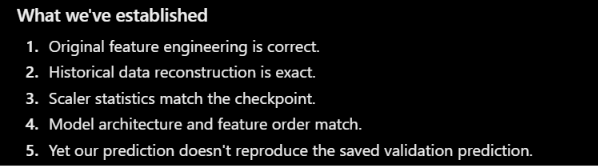

In [ ]:
progress = checkpoint.get("training_progress")

print("Training progress type:", type(progress))

if isinstance(progress, dict):
    for key, value in progress.items():
        print(f"\n{key}:")
        print(str(value)[:1000])
else:
    print(str(progress)[:3000])

Training progress type: <class 'dict'>

epoch:
5

file_order:
[6, 8, 5, 1, 18, 2, 23, 28, 4, 24, 12, 0, 29, 3, 16, 15, 27, 7, 21, 30, 25, 17, 10, 14, 19, 20, 26, 13, 9, 11, 22]

next_file_position:
31

loss_sum:
7315591.606056333

samples:
45795980

batches:
22380

seconds:
463.02797501400164


In [ ]:
print("Training history type:", type(checkpoint["training_history"]))

for i, epoch_data in enumerate(checkpoint["training_history"], 1):
    print(f"\nEpoch {i}:")
    print(epoch_data)

Training history type: <class 'list'>

Epoch 1:
{'epoch': 1, 'train_loss': 0.16222534619934165, 'train_samples': 45795980, 'train_seconds': 477.08256971, 'validation_loss': 0.22097951441392263, 'mae': np.float64(0.9194042639795039), 'rmse': np.float64(2.325084654222281), 'wape': np.float64(70.7906278151061), 'validation_samples': 12531390, 'validation_seconds': 178.07516604199998}

Epoch 2:
{'epoch': 2, 'train_loss': 0.16074653764765615, 'train_samples': 45795980, 'train_seconds': 465.14941372299995, 'validation_loss': 0.2157997908685804, 'mae': np.float64(0.8894732770807476), 'rmse': np.float64(2.1373648868520636), 'wape': np.float64(68.48605578221427), 'validation_samples': 12531390, 'validation_seconds': 180.171023482}

Epoch 3:
{'epoch': 3, 'train_loss': 0.160227559678949, 'train_samples': 45795980, 'train_seconds': 461.4431959770002, 'validation_loss': 0.21713523163577847, 'mae': np.float64(0.902027283940807), 'rmse': np.float64(2.3154590763541094), 'wape': np.float64(69.452666512

### Prediction file's structure and columns

In [ ]:
import glob
import pandas as pd

prediction_files = sorted(glob.glob(
    f"{BASE}/Data/processed/full_dataset/predictions/lstm_predictions_chunk_*.parquet"
))

print("Prediction files:", len(prediction_files))

sample = pd.read_parquet(prediction_files[0])

print("\nColumns:")
print(sample.columns.tolist())

print("\nShape:", sample.shape)
print("\nSample rows:")
print(sample.head(5).to_string(index=False))

Prediction files: 31

Columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'date', 'sales', 'lstm_prediction']

Shape: (411000, 9)

Sample rows:
                           id       item_id   dept_id  cat_id store_id state_id       date  sales  lstm_prediction
HOBBIES_1_001_CA_1_evaluation HOBBIES_1_001 HOBBIES_1 HOBBIES     CA_1       CA 2015-04-08      2         0.384569
HOBBIES_1_001_CA_1_evaluation HOBBIES_1_001 HOBBIES_1 HOBBIES     CA_1       CA 2015-04-09      1         0.404895
HOBBIES_1_001_CA_1_evaluation HOBBIES_1_001 HOBBIES_1 HOBBIES     CA_1       CA 2015-04-10      1         0.507918
HOBBIES_1_001_CA_1_evaluation HOBBIES_1_001 HOBBIES_1 HOBBIES     CA_1       CA 2015-04-11      1         0.621789
HOBBIES_1_001_CA_1_evaluation HOBBIES_1_001 HOBBIES_1 HOBBIES     CA_1       CA 2015-04-12      0         0.498152


In [ ]:
test_id = "FOODS_1_001_CA_1_evaluation"

saved = pd.concat(
    [pd.read_parquet(f) for f in prediction_files],
    ignore_index=True
)

test_saved = (
    saved[saved["id"] == test_id]
    .sort_values("date")
    .reset_index(drop=True)
)

print("Rows:", len(test_saved))
print("\nFirst 5:")
print(test_saved.head().to_string(index=False))

print("\nLast 10:")
print(test_saved.tail(10).to_string(index=False))

print("\nDate range:")
print(test_saved["date"].min(), "to", test_saved["date"].max())

Rows: 411

First 5:
                         id     item_id dept_id cat_id store_id state_id       date  sales  lstm_prediction
FOODS_1_001_CA_1_evaluation FOODS_1_001 FOODS_1  FOODS     CA_1       CA 2015-04-08      1         0.278306
FOODS_1_001_CA_1_evaluation FOODS_1_001 FOODS_1  FOODS     CA_1       CA 2015-04-09      0         0.316263
FOODS_1_001_CA_1_evaluation FOODS_1_001 FOODS_1  FOODS     CA_1       CA 2015-04-10      0         0.369402
FOODS_1_001_CA_1_evaluation FOODS_1_001 FOODS_1  FOODS     CA_1       CA 2015-04-11      1         0.408084
FOODS_1_001_CA_1_evaluation FOODS_1_001 FOODS_1  FOODS     CA_1       CA 2015-04-12      2         0.349443

Last 10:
                         id     item_id dept_id cat_id store_id state_id       date  sales  lstm_prediction
FOODS_1_001_CA_1_evaluation FOODS_1_001 FOODS_1  FOODS     CA_1       CA 2016-05-13      2         0.645252
FOODS_1_001_CA_1_evaluation FOODS_1_001 FOODS_1  FOODS     CA_1       CA 2016-05-14      3         0.89912

In [ ]:
print("Actual sales statistics:")
print(test_saved["sales"].describe())

print("\nSaved prediction statistics:")
print(test_saved["lstm_prediction"].describe())

print("\nPrediction range:")
print("Min:", test_saved["lstm_prediction"].min())
print("Max:", test_saved["lstm_prediction"].max())

print("\nLast 5 predictions:")
print(test_saved[["date", "sales", "lstm_prediction"]].tail().to_string(index=False))

Actual sales statistics:
count    411.000000
mean       0.688564
std        1.043138
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        6.000000
Name: sales, dtype: float64

Saved prediction statistics:
count    411.000000
mean       0.394126
std        0.133527
min        0.034016
25%        0.300914
50%        0.356043
75%        0.470751
max        0.904458
Name: lstm_prediction, dtype: float64

Prediction range:
Min: 0.034015907991837596
Max: 0.9044579409438998

Last 5 predictions:
      date  sales  lstm_prediction
2016-05-18      0         0.506795
2016-05-19      1         0.486122
2016-05-20      0         0.703399
2016-05-21      0         0.840730
2016-05-22      0         0.621495


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual = test_saved["sales"].to_numpy(dtype=np.float64)
predicted = test_saved["lstm_prediction"].to_numpy(dtype=np.float64)

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
wape = np.abs(actual - predicted).sum() / actual.sum() * 100

print("Product-level validation metrics")
print("MAE:", round(mae, 6))
print("RMSE:", round(rmse, 6))
print("WAPE:", round(wape, 2), "%")
print("Actual total:", actual.sum())
print("Predicted total:", round(predicted.sum(), 3))


Product-level validation metrics
MAE: 0.752824
RMSE: 1.084536
WAPE: 109.33 %
Actual total: 283.0
Predicted total: 161.986


In [ ]:
# Select the product-store series with the highest sales
# during the last 28 historical days.

active_products = (
    history.groupby("id")["sales"]
    .sum()
    .sort_values(ascending=False)
)

test_id = active_products.index[0]

print("Selected product:", test_id)
print("Last 28-day sales:", active_products.iloc[0])

# Run the existing single-product forecasting function
forecast_result = forecast_one_product(test_id)

print("\nForecast result:")
print(forecast_result)

Selected product: FOODS_3_090_CA_3_evaluation
Last 28-day sales: 3357

Forecast result:
                             id       date  predicted_sales
0   FOODS_3_090_CA_3_evaluation 2016-05-23       364.706170
1   FOODS_3_090_CA_3_evaluation 2016-05-24       339.085619
2   FOODS_3_090_CA_3_evaluation 2016-05-25       509.539206
3   FOODS_3_090_CA_3_evaluation 2016-05-26       635.062908
4   FOODS_3_090_CA_3_evaluation 2016-05-27       717.364610
5   FOODS_3_090_CA_3_evaluation 2016-05-28       760.790524
6   FOODS_3_090_CA_3_evaluation 2016-05-29       884.804403
7   FOODS_3_090_CA_3_evaluation 2016-05-30       861.762924
8   FOODS_3_090_CA_3_evaluation 2016-05-31       919.913854
9   FOODS_3_090_CA_3_evaluation 2016-06-01      1136.145913
10  FOODS_3_090_CA_3_evaluation 2016-06-02      1038.346795
11  FOODS_3_090_CA_3_evaluation 2016-06-03      1033.363142
12  FOODS_3_090_CA_3_evaluation 2016-06-04      1179.963267
13  FOODS_3_090_CA_3_evaluation 2016-06-05      1175.153844
14  FOODS_3_

## Full Future Forecasting

In [ ]:
# ============================================================
# RETAIL DEMAND FORECASTING
# DAY 15 - CORRECTED FUTURE FORECASTING PIPELINE
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

FORECAST_DIR = (
    f"{BASE}/Data/processed/full_dataset/"
    "future_forecasts_corrected_v2"
)

os.makedirs(FORECAST_DIR, exist_ok=True)

FORECAST_DAYS = 28
SEQ_LENGTH = 28
BATCH_SIZE = 256

DEVICE = next(model.parameters()).device

model.eval()

print("Device:", DEVICE)
print("Batch size:", BATCH_SIZE)
print("Forecast horizon:", FORECAST_DAYS)


# ============================================================
# 2. PREPARE DATA
# ============================================================

history["date"] = pd.to_datetime(history["date"])
future["date"] = pd.to_datetime(future["date"])

history = history.sort_values(
    ["id", "date"]
).reset_index(drop=True)

future = future.sort_values(
    ["id", "date"]
).reset_index(drop=True)

series_ids = sorted(history["id"].unique())

history_groups = {
    sid: group.tail(SEQ_LENGTH).copy()
    for sid, group in history.groupby("id", sort=False)
}

future_groups = {
    sid: group.sort_values("date").reset_index(drop=True)
    for sid, group in future.groupby("id", sort=False)
}

assert len(series_ids) == 30490
assert len(history_groups) == 30490
assert len(future_groups) == 30490

assert all(
    len(history_groups[sid]) == SEQ_LENGTH
    for sid in series_ids
)

assert all(
    len(future_groups[sid]) == FORECAST_DAYS
    for sid in series_ids
)

print("Historical series:", len(history_groups))
print("Future series:", len(future_groups))


# ============================================================
# 3. FEATURE SCALING
# ============================================================

def scale_history(df):

    x = df[HISTORY_FEATURES].to_numpy(
        dtype=np.float32
    ).copy()

    # Standardize first 9 numerical features
    x[:, :9] = scaler.transform(
        x[:, :9]
    )

    return x


def scale_future(df):

    x = df[FUTURE_FEATURES].to_numpy(
        dtype=np.float32
    ).copy()

    # Price
    x[:, 0] = (
        x[:, 0] - scaler.mean_[1]
    ) / scaler.scale_[1]

    # Day of week
    x[:, 2] = (
        x[:, 2] - scaler.mean_[7]
    ) / scaler.scale_[7]

    # Month
    x[:, 3] = (
        x[:, 3] - scaler.mean_[8]
    ) / scaler.scale_[8]

    return x


# ============================================================
# 4. RECURSIVE FORECASTING FUNCTION
# ============================================================

def forecast_batch(batch_ids):

    batch_history = []
    batch_future = []
    sales_buffers = []
    future_frames = []

    # Prepare batch
    for sid in batch_ids:

        hist = history_groups[sid]
        fut = future_groups[sid]

        batch_history.append(
            scale_history(hist)
        )

        batch_future.append(
            scale_future(fut)
        )

        sales_buffers.append(
            hist["sales"].to_numpy(
                dtype=np.float32
            ).tolist()
        )

        future_frames.append(fut)

    batch_history = np.asarray(
        batch_history,
        dtype=np.float32
    )

    batch_future = np.asarray(
        batch_future,
        dtype=np.float32
    )

    predictions = np.zeros(
        (len(batch_ids), FORECAST_DAYS),
        dtype=np.float32
    )

    # Recursive daily forecasting
    with torch.inference_mode():

        for day in range(FORECAST_DAYS):

            X_history = torch.from_numpy(
                batch_history
            ).to(DEVICE)

            X_future = torch.from_numpy(
                batch_future[:, day, :]
            ).to(DEVICE)

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=(DEVICE.type == "cuda")
            ):

                output = model(
                    X_history,
                    X_future
                )

            raw_output = (
                output.float()
                .cpu()
                .numpy()
                .reshape(-1)
            )

            # ------------------------------------------------
            # IMPORTANT: REVERSE TARGET STANDARDIZATION
            # ------------------------------------------------

            predicted_log = (
                raw_output * scaler.scale_[0]
                + scaler.mean_[0]
            )

            # Convert log1p(sales) into actual sales
            predicted_sales = np.expm1(
                np.clip(predicted_log, 0, 15)
            )

            predicted_sales = np.maximum(
                predicted_sales, 0
            )

            predictions[:, day] = predicted_sales

            # ------------------------------------------------
            # UPDATE HISTORY FOR NEXT DAY
            # ------------------------------------------------

            for i in range(len(batch_ids)):

                sales_buffer = sales_buffers[i]

                future_row = future_frames[i].iloc[day]

                predicted = float(
                    predicted_sales[i]
                )

                new_row = np.array([

                    np.log1p(predicted),

                    future_row["sell_price_filled"],

                    sales_buffer[-1],

                    sales_buffer[-7],

                    sales_buffer[-28],

                    np.mean(sales_buffer[-7:]),

                    np.mean(sales_buffer[-28:]),

                    future_row["day_of_week"],

                    future_row["month"],

                    future_row["price_missing"],

                    future_row["is_event"],

                    future_row["snap_CA"],

                    future_row["snap_TX"],

                    future_row["snap_WI"]

                ], dtype=np.float32)

                # Standardize historical features
                new_row[:9] = (
                    new_row[:9] - scaler.mean_
                ) / scaler.scale_

                # Update 28-day history window
                batch_history[i] = np.concatenate(
                    [
                        batch_history[i][1:],
                        new_row.reshape(1, -1)
                    ],
                    axis=0
                )

                # Update raw sales buffer
                sales_buffer.append(predicted)

    return predictions


# ============================================================
# 5. FORECAST ALL 30,490 SERIES
# ============================================================

total_batches = int(
    np.ceil(len(series_ids) / BATCH_SIZE)
)

print("\nStarting forecasting...")
print("Total batches:", total_batches)

for batch_number in tqdm(
    range(total_batches),
    desc="Forecasting"
):

    start = batch_number * BATCH_SIZE

    end = min(
        start + BATCH_SIZE,
        len(series_ids)
    )

    batch_ids = series_ids[start:end]

    batch_predictions = forecast_batch(
        batch_ids
    )

    batch_results = []

    for i, sid in enumerate(batch_ids):

        dates = future_groups[sid]["date"]

        batch_results.append(
            pd.DataFrame({

                "id": sid,

                "date": dates.to_numpy(),

                "predicted_sales": batch_predictions[i]

            })
        )

    batch_df = pd.concat(
        batch_results,
        ignore_index=True
    )

    output_path = (
        f"{FORECAST_DIR}/"
        f"forecast_batch_{batch_number:03d}.parquet"
    )

    batch_df.to_parquet(
        output_path,
        index=False
    )

    del batch_predictions
    del batch_results
    del batch_df

    gc.collect()


# ============================================================
# 6. COMBINE FORECAST FILES
# ============================================================

print("\nCombining forecast files...")

forecast_files = sorted([
    os.path.join(FORECAST_DIR, f)
    for f in os.listdir(FORECAST_DIR)
    if f.startswith("forecast_batch_")
    and f.endswith(".parquet")
])

assert len(forecast_files) == total_batches

forecast_df = pd.concat(
    [
        pd.read_parquet(path)
        for path in forecast_files
    ],
    ignore_index=True
)

forecast_df["date"] = pd.to_datetime(
    forecast_df["date"]
)

forecast_df = forecast_df.sort_values(
    ["id", "date"]
).reset_index(drop=True)


# ============================================================
# 7. FORECAST SUMMARY
# ============================================================

summary = (
    forecast_df.groupby("id")
    .agg(

        forecast_total=(
            "predicted_sales",
            "sum"
        ),

        average_daily_demand=(
            "predicted_sales",
            "mean"
        ),

        peak_daily_demand=(
            "predicted_sales",
            "max"
        )

    )
    .reset_index()
)


# ============================================================
# 8. SAVE FINAL OUTPUTS
# ============================================================

forecast_df.to_parquet(
    f"{FORECAST_DIR}/future_forecasts.parquet",
    index=False
)

forecast_df.to_csv(
    f"{FORECAST_DIR}/future_forecasts.csv",
    index=False
)

summary.to_parquet(
    f"{FORECAST_DIR}/forecast_summary.parquet",
    index=False
)

summary.to_csv(
    f"{FORECAST_DIR}/forecast_summary.csv",
    index=False
)


# ============================================================
# 9. FINAL REPORT
# ============================================================

print("\n" + "=" * 60)
print("CORRECTED FUTURE FORECASTING COMPLETED")
print("=" * 60)

print("Products / Stores:", summary["id"].nunique())

print("Forecast days:", forecast_df["date"].nunique())

print("Total predictions:", len(forecast_df))

print("Forecast start:", forecast_df["date"].min())

print("Forecast end:", forecast_df["date"].max())

print("\nForecast Statistics:")

print(
    forecast_df["predicted_sales"].describe()
)

print("\nTop 10 Demand Products:")

print(
    summary.sort_values(
        "forecast_total",
        ascending=False
    ).head(10).to_string(index=False)
)

print("\nForecast files saved at:")

print(FORECAST_DIR)

print("\nMain files:")
print("1. future_forecasts.parquet")
print("2. future_forecasts.csv")
print("3. forecast_summary.parquet")
print("4. forecast_summary.csv")

print("\n" + "=" * 60)

Device: cpu
Batch size: 256
Forecast horizon: 28
Historical series: 30490
Future series: 30490

Starting forecasting...
Total batches: 120


Forecasting:   0%|          | 0/120 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Combining forecast files...

CORRECTED FUTURE FORECASTING COMPLETED
Products / Stores: 30490
Forecast days: 28
Total predictions: 853720
Forecast start: 2016-05-23 00:00:00
Forecast end: 2016-06-19 00:00:00

Forecast Statistics:
count    853720.000000
mean          0.858323
std           1.687794
min           0.000000
25%           0.139006
50%           0.342938
75%           0.832202
max          73.081833
Name: predicted_sales, dtype: float64

Top 10 Demand Products:
                         id  forecast_total  average_daily_demand  peak_daily_demand
FOODS_3_090_CA_3_evaluation     1253.028442             44.751015          73.081833
FOODS_3_586_TX_2_evaluation     1204.272705             43.009739          69.158417
FOODS_3_090_WI_3_evaluation     1054.173706             37.649059          64.432823
FOODS_3_586_CA_3_evaluation     1025.277954             36.617069          58.538548
FOODS_3_090_TX_3_evaluation      984.514343             35.161228          59.133617
FOODS_3_586_T